# Trabajo Práctico Especial: Staged Kidney Disease (CKD-NHANES 2021-2023)

## Carga de datos

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import shapiro
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("CKD-NHANES/CKD_NHANES_2021_2023.csv", sep = ",", encoding = "latin1", on_bad_lines= "skip")
pd.set_option("display.max_columns", None)
data.head()

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


## Exploración inicial

### Tipos de datos y valores nulos

In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  str    
 3   ethnicity                 11933 non-null  str    
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosphorus       

In [3]:
data.isna().sum()

participant_id                  0
age                             0
gender                          0
ethnicity                       0
education_level              4139
poverty_income_ratio         2041
bmi                          3462
weight_kg                    3179
height_cm                    3434
bp_systolic                  4416
bp_diastolic                 4416
serum_creatinine             5607
blood_urea_nitrogen          5607
albumin_serum                5567
phosphorus                   5611
bicarbonate                  5608
calcium                      5571
uric_acid                    5604
urine_creatinine             3779
urine_albumin                3780
albumin_creatinine_ratio     3780
diabetes_diagnosed            193
insulin_use                 10852
diabetes_pills               9652
ever_smoked                  3798
current_smoker               8690
egfr                         5607
ckd_stage                       0
ckd_present                     0
dtype: int64

### Frecuencia de valores por columna

In [4]:
cols = ["participant_id", "age", "gender", "ethnicity","education_level", "poverty_income_ratio", "bmi", "weight_kg", "height_cm", "bp_systolic", "bp_diastolic", "serum_creatinine", "blood_urea_nitrogen", "albumin_serum", "phosphorus", "bicarbonate", "calcium", "uric_acid", "urine_creatinine", "urine_albumin", "albumin_creatinine_ratio", "diabetes_diagnosed", "insulin_use", "diabetes_pills", "ever_smoked", "current_smoker", "egfr", "ckd_stage", "ckd_present"]
for c in cols:
    print(data[c].value_counts())
    print()

participant_id
130378.0    1
130379.0    1
130380.0    1
130381.0    1
130382.0    1
           ..
142306.0    1
142307.0    1
142308.0    1
142309.0    1
142310.0    1
Name: count, Length: 11933, dtype: int64

age
80.0    525
8.0     257
5.0     246
4.0     229
12.0    228
       ... 
79.0     82
23.0     82
47.0     76
78.0     73
20.0     71
Name: count, Length: 81, dtype: int64

gender
Female    6358
Male      5575
Name: count, dtype: int64

ethnicity
Non-Hispanic White    6217
Non-Hispanic Black    1597
Other Hispanic        1373
Mexican American      1117
Other/Multiracial      948
Non-Hispanic Asian     681
Name: count, dtype: int64

education_level
5.0    2625
4.0    2370
3.0    1749
2.0     666
1.0     373
9.0      11
Name: count, dtype: int64

poverty_income_ratio
5.000000e+00    2149
5.397605e-79     100
1.850000e+00      74
2.160000e+00      64
1.370000e+00      58
                ... 
4.700000e+00       1
1.630000e+00       1
2.140000e+00       1
4.280000e+00       1
4.870

## Limpieza de datos

### Conversión de columnas a enteros

Estas columnas vienen guardadas como decimales en el archivo, pero sus valores son enteros: códigos de categorías (educación, diabetes, tabaquismo), identificadores, edad o mediciones sin decimales. Por eso las redondeamos y las pasamos a `Int64`, el tipo entero de pandas que admite valores nulos.

In [5]:
columnas_enteras = ["participant_id", "age", "education_level", "bp_systolic", "bp_diastolic",
                    "blood_urea_nitrogen", "bicarbonate", "urine_creatinine", "diabetes_diagnosed",
                    "insulin_use", "diabetes_pills", "ever_smoked", "current_smoker", "ckd_present"]

data[columnas_enteras] = data[columnas_enteras].round().astype("Int64")

### Códigos de falta de respuesta (7 y 9)

Según la metadata, en las variables de cuestionario el **7** significa "se negó a responder" y el **9** "no sabe". No son categorías reales, así que los reemplazamos por valores nulos (`NaN`) para que no se cuenten como respuestas.

In [6]:
columnas_cuestionario = ["education_level", "diabetes_diagnosed", "diabetes_pills", "ever_smoked", "current_smoker"]

for columna in columnas_cuestionario:
    data[columna] = data[columna].replace([7, 9], np.nan)

data[columnas_cuestionario].isna().sum()

education_level       4150
diabetes_diagnosed     197
diabetes_pills        9659
ever_smoked           3812
current_smoker        8690
dtype: int64

### Verificación: diabetes vs medicación

Revisamos si hay personas sin diabetes diagnosticada (`diabetes_diagnosed == 2`) que usan insulina o pastillas para la diabetes.

In [7]:
sin_diabetes = data["diabetes_diagnosed"] == 2
con_insulina = data["insulin_use"] == 1
con_pastillas = data["diabetes_pills"] == 1

print(f"Sin diabetes y con insulina: {(sin_diabetes & con_insulina).sum()}")
print(f"Sin diabetes y con pastillas: {(sin_diabetes & con_pastillas).sum()}")
print(f"Sin diabetes y con insulina o pastillas: {(sin_diabetes & (con_insulina | con_pastillas)).sum()}")

Sin diabetes y con insulina: 0
Sin diabetes y con pastillas: 60
Sin diabetes y con insulina o pastillas: 60


Nadie sin diagnóstico usa insulina. Hay 60 personas sin diagnóstico que toman pastillas, pero estas pastillas no indican necesariamente que la persona tenga diabetes: también se recetan, por ejemplo, en casos de prediabetes. Por eso decidimos no modificar esos registros.

### Verificación de valores fuera de rango

Contamos los registros con valores imposibles o muy poco plausibles para una persona en cada medición: edades negativas o mayores a 80 (el archivo agrupa en 80 a quienes tienen 80 años o más) y valores extremos en medidas corporales, presión arterial, análisis de sangre, orina y eGFR.

In [8]:
print((data["age"] < 0).sum())
print((data["age"] > 80).sum())

# Medidas corporales y presión arterial
print((data["bmi"] <= 0).sum())
print((data["bp_systolic"] <= 0).sum())
print((data["bp_systolic"] >= 300).sum())
print((data["bp_diastolic"] <= 0).sum())
print((data["bp_diastolic"] >= 360).sum())

# Análisis de sangre
print((data["serum_creatinine"] <= 0).sum())
print((data["serum_creatinine"] >= 53).sum())
print((data["blood_urea_nitrogen"] <= 0).sum())
print((data["albumin_serum"] <= 1.0).sum())
print((data["albumin_serum"] >= 8.1).sum())
print((data["phosphorus"] <= 0.3).sum())
print((data["phosphorus"] >= 12.0).sum())
print((data["bicarbonate"] <= 3).sum())
print((data["bicarbonate"] >= 60).sum())
print((data["calcium"] <= 6.0).sum())
print((data["calcium"] >= 17.0).sum())
print((data["uric_acid"] <= 1.0).sum())
print((data["uric_acid"] >= 20.0).sum())

# Análisis de orina
print((data["urine_creatinine"] <= 2).sum())
print((data["urine_albumin"] <= 0).sum())
print((data["urine_albumin"] >= 10000).sum())
print((data["albumin_creatinine_ratio"] <= 0).sum())

# Variable derivada
print((data["egfr"] <= 0).sum())

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


Ninguna variable tiene valores fuera de rango, por lo que no eliminamos ni modificamos ningún registro por este motivo.

### Registros duplicados

Verificamos que no haya filas repetidas ni participantes con el mismo identificador.

In [9]:
print(f"Filas duplicadas: {data.duplicated().sum()}")
print(f"participant_id duplicados: {data['participant_id'].duplicated().sum()}")

Filas duplicadas: 0
participant_id duplicados: 0


### Etapas de CKD con nombres simplificados

Los valores de `ckd_stage` que indican una etapa tienen espacios, mayúsculas y una descripción entre paréntesis (por ejemplo, `Stage 3a (Mild-Moderate)`). Para que sean más cómodos de usar en los filtros y en los gráficos, los reemplazamos por nombres cortos: `Stage1`, `Stage2`, `Stage3a`, `Stage3b`, `Stage4` y `Stage5`. Los valores `No CKD` y `Unknown` los dejamos igual.

In [10]:
nombres_etapas = {
    "Stage 1 (Kidney Damage)": "Stage1",
    "Stage 2 (Mildly Decreased)": "Stage2",
    "Stage 3a (Mild-Moderate)": "Stage3a",
    "Stage 3b (Moderate-Severe)": "Stage3b",
    "Stage 4 (Severely Decreased)": "Stage4",
    "Stage 5 (Kidney Failure)": "Stage5"
}

data["ckd_stage"] = data["ckd_stage"].replace(nombres_etapas)

data["ckd_stage"].value_counts()

ckd_stage
Unknown    5607
No CKD     3592
Stage2     1875
Stage1      382
Stage3a     341
Stage3b      97
Stage4       28
Stage5       11
Name: count, dtype: int64

### Valores faltantes de eGFR

`egfr` no es una medición directa: se calcula con la ecuación CKD-EPI 2021 a partir de tres variables, la **creatinina sérica**, la **edad** y el **sexo**. Si a una persona le falta el eGFR pero tiene esas tres variables, se podría recalcular. Por eso analizamos cuántas observaciones no tienen eGFR y cuál de esas variables es la que falta.

In [11]:
sin_egfr = data[data["egfr"].isna()]

print(f"Observaciones sin eGFR: {len(sin_egfr)} de {len(data)} ({len(sin_egfr) / len(data) * 100:.2f}%)")
print()
print("Variables necesarias para calcular el eGFR que faltan en esas observaciones:")
print(f"- Creatinina sérica: {sin_egfr['serum_creatinine'].isna().sum()}")
print(f"- Edad: {sin_egfr['age'].isna().sum()}")
print(f"- Sexo: {sin_egfr['gender'].isna().sum()}")
print()
print(f"Observaciones con creatinina pero sin eGFR: {(data['serum_creatinine'].notna() & data['egfr'].isna()).sum()}")

Observaciones sin eGFR: 5607 de 11933 (46.99%)

Variables necesarias para calcular el eGFR que faltan en esas observaciones:
- Creatinina sérica: 5607
- Edad: 0
- Sexo: 0

Observaciones con creatinina pero sin eGFR: 0


Vemos que todas las observaciones sin eGFR son también las que no tienen creatinina; la edad y el sexo están completos. No hay ningún caso con creatinina y sin eGFR, así que **no hay ningún eGFR que podamos recalcular**: imputarlo implicaría inventar el valor de creatinina, que es un análisis de sangre que nunca se hizo. Por eso decidimos no imputarlo.

## Análisis exploratorio de los datos

### Presencia y etapas de CKD

Graficamos cuántas personas tienen CKD (`ckd_present`) y en qué etapa están (`ckd_stage`). Dejamos afuera los `Unknown`, porque no tienen el eGFR calculado y no se sabe si tienen CKD. Las barras de las etapas están ordenadas de mayor a menor cantidad.

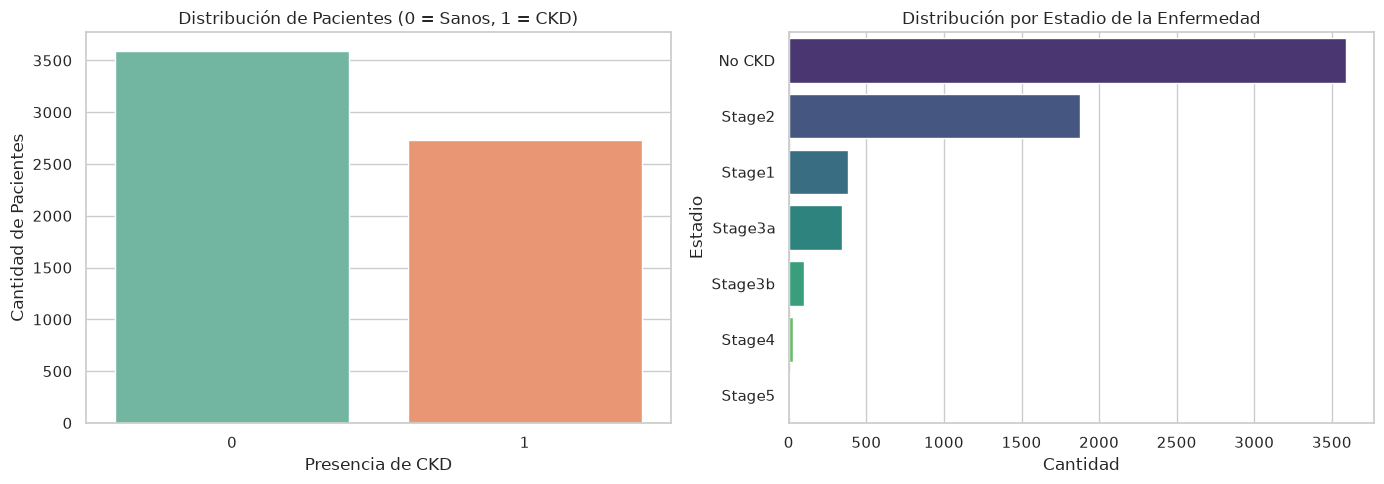

ckd_present
0    3592
1    2734
Name: count, dtype: Int64

ckd_stage
No CKD     3592
Stage2     1875
Stage1      382
Stage3a     341
Stage3b      97
Stage4       28
Stage5       11
Name: count, dtype: int64


In [12]:
datos_con_etapa = data[data["ckd_stage"] != "Unknown"]
orden_etapas = datos_con_etapa["ckd_stage"].value_counts().index

with sns.axes_style("whitegrid"), sns.plotting_context("notebook"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.countplot(x="ckd_present", data=datos_con_etapa, hue="ckd_present", palette="Set2", legend=False, ax=axes[0])
    axes[0].set_title("Distribución de Pacientes (0 = Sanos, 1 = CKD)")
    axes[0].set_xlabel("Presencia de CKD")
    axes[0].set_ylabel("Cantidad de Pacientes")

    sns.countplot(y="ckd_stage", data=datos_con_etapa, order=orden_etapas, hue="ckd_stage", hue_order=orden_etapas, palette="viridis", legend=False, ax=axes[1])
    axes[1].set_title("Distribución por Estadio de la Enfermedad")
    axes[1].set_xlabel("Cantidad")
    axes[1].set_ylabel("Estadio")

    plt.tight_layout()
    plt.show()

print(datos_con_etapa["ckd_present"].value_counts())
print()
print(datos_con_etapa["ckd_stage"].value_counts())

Sin los `Unknown`, 3592 personas no tienen CKD y 2734 sí. La mayoría de los casos de CKD están en `Stage2` (1875), mientras que en la etapa más avanzada, `Stage5`, que corresponde a la falla renal crónica (CKF), hay solo 11 personas.

### Distribución de las variables continuas

Graficamos un histograma de las principales variables continuas: la edad, el BMI, la presión sistólica y el eGFR. La línea azul es una estimación suave de la forma de la distribución (`kde`).

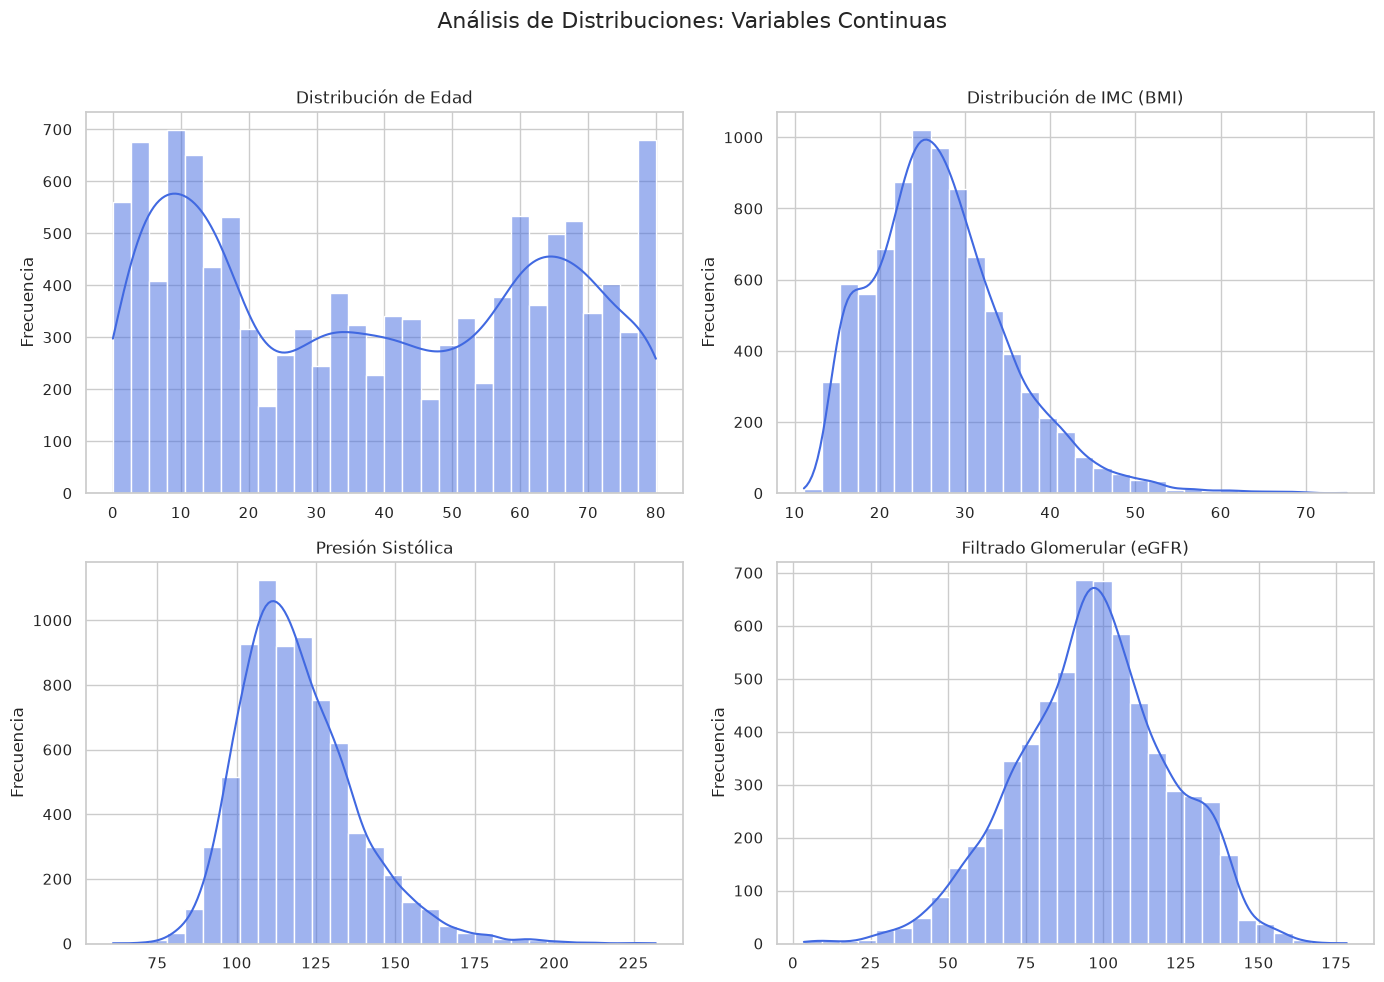

,age,bmi,bp_systolic,egfr
count,11933.0,8471.00,7517.0,6326.00
mean,38.32,27.25,119.29,96.60
std,25.6,8.14,18.56,24.63
min,0.0,11.10,61.0,3.51
25%,13.0,21.60,106.0,80.50
50%,37.0,26.40,117.0,97.03
75%,62.0,31.70,130.0,112.66
max,80.0,74.80,232.0,178.43


In [13]:
variables_continuas = {"age": "Distribución de Edad", "bmi": "Distribución de IMC (BMI)",
                       "bp_systolic": "Presión Sistólica", "egfr": "Filtrado Glomerular (eGFR)"}

with sns.axes_style("whitegrid"), sns.plotting_context("notebook"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("Análisis de Distribuciones: Variables Continuas", fontsize=16)

    for ax, (columna, titulo) in zip(axes.flatten(), variables_continuas.items()):
        sns.histplot(data[columna], bins=30, kde=True, color="royalblue", ax=ax)
        ax.set_title(titulo)
        ax.set_xlabel("")
        ax.set_ylabel("Frecuencia")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

data[list(variables_continuas)].describe().round(2)

La edad tiene dos grandes grupos: uno de niños y jóvenes hasta los 20 años y otro de adultos mayores de 60, con el máximo en 80 (la edad tope que registra el dataset). El BMI y la presión sistólica tienen una asimetría hacia la derecha, con una cola de valores altos. El eGFR es más simétrico, con una cola hacia valores bajos que corresponde a las personas con poco filtrado.

### Frecuencia de las variables categóricas

Graficamos la cantidad de personas en cada categoría del sexo, el diagnóstico de diabetes, el tabaquismo y el nivel educativo. Usamos los datos ya limpios, así que los códigos 7 y 9 no aparecen.

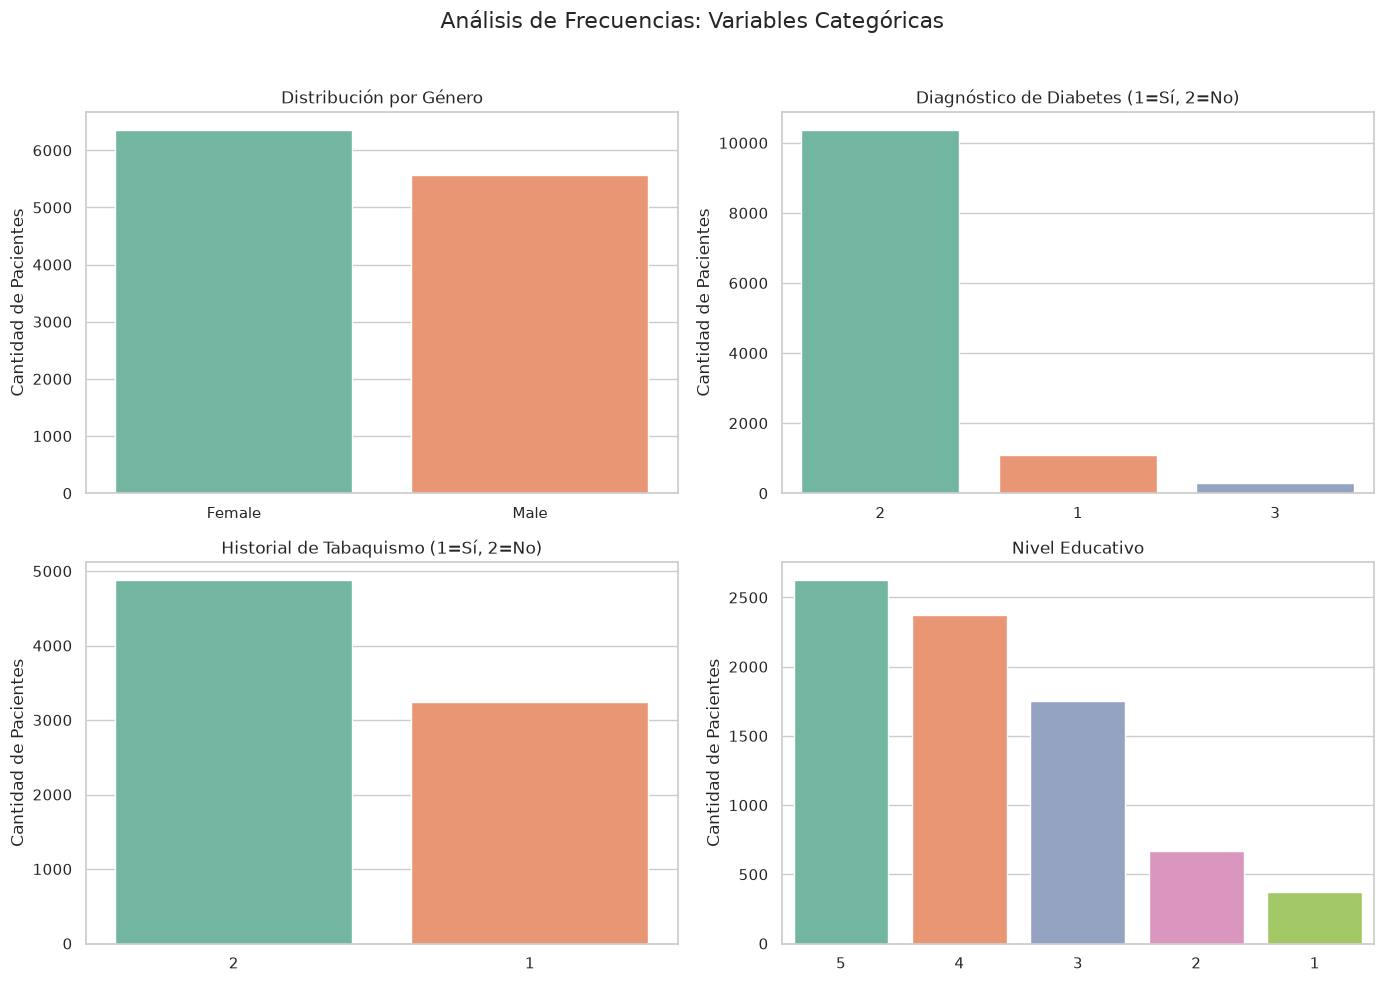

gender
Female    6358
Male      5575
Name: count, dtype: int64

diabetes_diagnosed
2    10371
1     1081
3      284
Name: count, dtype: Int64

ever_smoked
2    4878
1    3243
Name: count, dtype: Int64

education_level
5    2625
4    2370
3    1749
2     666
1     373
Name: count, dtype: Int64



In [14]:
variables_categoricas = {"gender": "Distribución por Género", "diabetes_diagnosed": "Diagnóstico de Diabetes (1=Sí, 2=No)",
                         "ever_smoked": "Historial de Tabaquismo (1=Sí, 2=No)", "education_level": "Nivel Educativo"}

with sns.axes_style("whitegrid"), sns.plotting_context("notebook"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("Análisis de Frecuencias: Variables Categóricas", fontsize=16)

    for ax, (columna, titulo) in zip(axes.flatten(), variables_categoricas.items()):
        orden = data[columna].value_counts().index
        sns.countplot(x=columna, data=data, order=orden, hue=columna, hue_order=orden, palette="Set2", legend=False, ax=ax)
        ax.set_title(titulo)
        ax.set_xlabel("")
        ax.set_ylabel("Cantidad de Pacientes")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

for columna in variables_categoricas:
    print(data[columna].value_counts())
    print()

La muestra está bastante equilibrada en sexo (6358 mujeres y 5575 hombres). En cambio, el diagnóstico de diabetes está muy desbalanceado: 1081 personas tienen diabetes diagnosticada (1), contra 10371 que no (2) y 284 *borderline* (3). Cerca del 40 % de los que respondieron fumó alguna vez (3243 de 8121), y los niveles educativos más frecuentes son los más altos (4 y 5).

## Análisis de la hipótesis univariada

### Planteo de la hipótesis

**Hipótesis:** el porcentaje de fumadores actuales de cigarrillo entre los adultos del dataset (NHANES 2021-2023) supera el porcentaje de fumadores adultos de EE.UU. informado por el CDC.

**Valor de referencia:** según el CDC (Centros para el Control y la Prevención de Enfermedades), el 11,5 % de los adultos (≥ 18 años) de EE.UU. fumaba cigarrillos en 2021.

Planteamos las hipótesis:
- **H0:** p = 0.115 (el porcentaje de fumadores del dataset es igual al de EE.UU.)
- **H1:** p > 0.115 (el porcentaje de fumadores del dataset supera al de EE.UU.)
- **Nivel de significancia:** α = 0.05

### Población observada

Tomamos los adultos que respondieron válidamente `ever_smoked` (1 o 2). La pregunta solo se hizo a mayores de 18 años.

Creamos la variable `fumador`, que vale 1 si la persona fuma actualmente y 0 si no. El promedio de esta variable es la proporción de fumadores.

In [15]:
alpha = 0.05
p0 = 0.115

poblacion_observada = data[data["ever_smoked"].isin([1, 2])]
n_total_observados = len(poblacion_observada)

fumador = poblacion_observada["current_smoker"].isin([1, 2]).astype(int)
total_fumadores_activos = fumador.sum()
no_fumadores_total = n_total_observados - total_fumadores_activos

proporcion_de_fumadores = fumador.mean()
porcentaje_de_fumadores = proporcion_de_fumadores * 100

print(f"Edad mínima de la población observada: {poblacion_observada['age'].min():.0f} años")
print(f"Total de población adulta observada: {n_total_observados}")
print(f"Total de fumadores activos: {total_fumadores_activos}")
print(f"Total de personas que no fuman actualmente: {no_fumadores_total}")
print(f"Porcentaje de fumadores activos: {porcentaje_de_fumadores:.2f}%")
print(f"Porcentaje de referencia (CDC, EE.UU.): {p0 * 100:.1f}%")

Edad mínima de la población observada: 18 años
Total de población adulta observada: 8121
Total de fumadores activos: 1190
Total de personas que no fuman actualmente: 6931
Porcentaje de fumadores activos: 14.65%
Porcentaje de referencia (CDC, EE.UU.): 11.5%


### Test t para una muestra

Usamos el **test t para una muestra**, que compara la media de una variable contra un valor fijo. Lo podemos usar porque, como `fumador` vale 0 o 1, su media es la proporción de fumadores.

**Supuestos:**
- **Independencia:** cada fila es una persona distinta.
- **Normalidad:** una variable 0/1 no es normal, así que no tiene sentido aplicarle Shapiro-Wilk. El test igual es válido porque lo que se compara es la media, y con una muestra grande (n = 8121, muy por encima de 30) la media se distribuye aproximadamente normal (teorema central del límite).
- **Homocedasticidad:** no corresponde, porque hay un solo grupo y no hay varianzas que comparar.

Usamos `alternative="greater"` porque H1 dice que la proporción es mayor a 0.115 (test unilateral).

In [16]:
resultado = stats.ttest_1samp(fumador, popmean=p0, alternative="greater")

t_estadistico = resultado.statistic
p_valor = resultado.pvalue
grados_libertad = resultado.df
limite_inferior = resultado.confidence_interval(confidence_level=0.95).low

print(f"Estadístico t: {t_estadistico:.4f}")
print(f"Valor p: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Límite inferior del IC 95% (unilateral): {limite_inferior * 100:.2f}%")

if p_valor < alpha:
    print("Se RECHAZA la hipótesis nula (H0). El porcentaje de fumadores activos es significativamente mayor al 11,5%.")
else:
    print("NO se rechaza la hipótesis nula (H0). No hay evidencia suficiente para afirmar que es mayor al 11,5%.")

Estadístico t: 8.0351
Valor p: 5.3331e-16
Grados de libertad: 8120
Límite inferior del IC 95% (unilateral): 14.01%
Se RECHAZA la hipótesis nula (H0). El porcentaje de fumadores activos es significativamente mayor al 11,5%.


#### Qué representa cada valor que devuelve el test
- **Estadístico t:** cuántos errores estándar está la proporción del dataset por encima (+) o por debajo (−) del 11,5 %. 
- **Valor p:** la probabilidad de obtener una proporción tan alta como la observada (o más alta) si H0 fuera cierta, es decir, si en realidad fumara el 11,5 %. Si es menor a α = 0.05, el resultado es muy difícil de explicar por azar y se rechaza H0.
- **Grados de libertad (n − 1):** definen qué distribución t se usa para calcular el p-valor. Con n tan grande, la distribución t es prácticamente igual a una normal.
- **Límite inferior del IC 95 %:** como el test es unilateral ("mayor que"), el intervalo es de la forma [límite inferior, infinito).

### Gráfico: proporción del dataset

Usamos un gráfico de barras, que sirve para comparar valores entre categorías:
- **Barra azul:** porcentaje de fumadores del dataset, con su intervalo de confianza del 95 % como barra de error (la "rayita" negra).
- **Barra gris:** porcentaje de referencia del CDC.
- **Línea roja punteada:** el valor de H0 (11,5 %).

Si toda la barra de error de la barra azul queda por encima de la línea roja, la diferencia no se explica por el azar del muestreo. Eso coincide con rechazar H0. Si la barra de error tocara o cruzara la línea, no habría evidencia suficiente.

IC 95% bilateral: [13.88%, 15.42%]


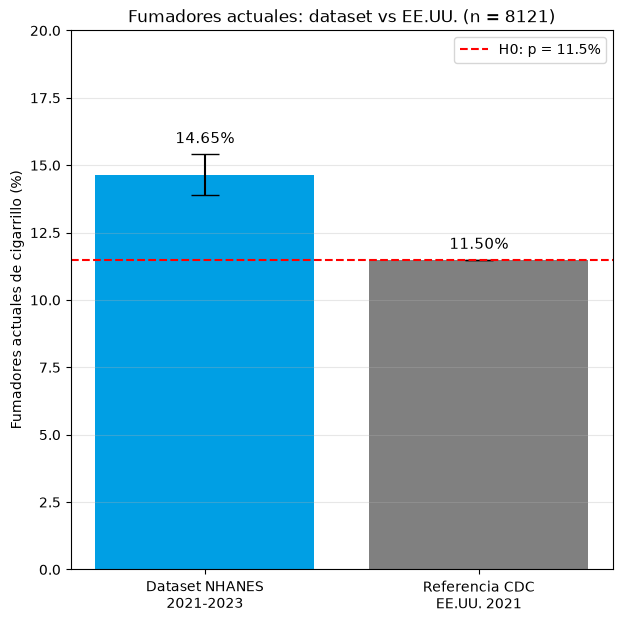

In [17]:
ic_bilateral = stats.ttest_1samp(fumador, popmean=p0).confidence_interval(confidence_level=0.95)
error_inferior = (proporcion_de_fumadores - ic_bilateral.low) * 100
error_superior = (ic_bilateral.high - proporcion_de_fumadores) * 100

print(f"IC 95% bilateral: [{ic_bilateral.low * 100:.2f}%, {ic_bilateral.high * 100:.2f}%]")

categorias = ["Dataset NHANES\n2021-2023", "Referencia CDC\nEE.UU. 2021"]
valores = [porcentaje_de_fumadores, p0 * 100]

plt.figure(figsize=(7, 7))
plt.bar(categorias, valores, color=["#009FE4", "gray"],
        yerr=[[error_inferior, 0], [error_superior, 0]], capsize=10)
plt.axhline(p0 * 100, color="red", linestyle="--", label=f"H0: p = {p0 * 100:.1f}%")

plt.text(0, porcentaje_de_fumadores + error_superior + 0.4, f"{porcentaje_de_fumadores:.2f}%", ha="center", fontsize=11)
plt.text(1, p0 * 100 + 0.4, f"{p0 * 100:.2f}%", ha="center", fontsize=11)

plt.ylabel("Fumadores actuales de cigarrillo (%)")
plt.title(f"Fumadores actuales: dataset vs EE.UU. (n = {n_total_observados})")
plt.ylim(0, 20)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.show()

### Conclusión

El porcentaje de fumadores actuales de cigarrillo en los adultos del dataset es 14,65 % (IC 95 %: 13,88 % – 15,42 %). Es mayor al 11,5 % que informa el CDC para EE.UU. en 2021.

El test t para una muestra da un p-valor muy menor a α = 0.05, por lo que rechazamos H0: el porcentaje de fumadores del dataset supera significativamente la cifra nacional. El gráfico lo confirma, porque el intervalo de confianza de la barra del dataset queda completo por encima de la línea del 11,5 %.

## Análisis de la hipótesis bivariada: existen diferencias en la capacidad de filtrado entre hombres y mujeres

### Planteo de la hipótesis

La capacidad de filtrado de los riñones se mide con la tasa de filtrado glomerular estimada (`egfr`, en mL/min/1,73 m²). Comparamos esta variable entre dos grupos independientes definidos por `gender`: hombres y mujeres.

- **H0:** no existen diferencias en la capacidad de filtrado (`egfr`) entre hombres y mujeres.
- **H1:** existen diferencias en la capacidad de filtrado (`egfr`) entre hombres y mujeres.
- **Nivel de significancia:** α = 0.05

### Población analizada

Tomamos las personas que tienen `egfr` calculado (las de etapa `Unknown` no lo tienen) y que son mayores de 18 años. Excluimos a los menores porque la ecuación CKD-EPI 2021, con la que se calculó el eGFR, está pensada para adultos, y la metadata advierte que el eGFR debe interpretarse con cautela en los extremos de edad.

A los adolescentes podríamos compararlos por separado y así tener una comparación de hombres y mujeres en su adolescencia y, por otro lado, la comparación en su adultez. Como mencionamos antes, el cálculo está pensado para los adultos, por lo que descartamos el análisis sobre los adolescentes.

Después separamos la variable `egfr` en los dos grupos a comparar.

In [18]:
adultos_con_egfr = data[(data["egfr"].notna()) & (data["age"] >= 18)]

egfr_hombres = adultos_con_egfr[adultos_con_egfr["gender"] == "Male"]["egfr"]
egfr_mujeres = adultos_con_egfr[adultos_con_egfr["gender"] == "Female"]["egfr"]

print(f"Adultos con eGFR: {len(adultos_con_egfr)}")
print(f"Hombres: {len(egfr_hombres)}")
print(f"Mujeres: {len(egfr_mujeres)}")

adultos_con_egfr.groupby("gender")["egfr"].describe().round(2)

Adultos con eGFR: 5658
Hombres: 2568
Mujeres: 3090


,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,3090.0,93.01,22.02,7.53,78.53,94.73,108.76,140.17
Male,2568.0,91.33,21.61,3.51,78.20,93.56,105.72,148.98


### Análisis gráfico de la hipótesis

Graficamos un **boxplot** de `egfr` para cada sexo. La línea del medio de cada caja es la mediana, y el *notch* (la muesca alrededor de la mediana) es un intervalo de confianza aproximado de la mediana: si los notches de los dos grupos no se superponen, es un indicio de que las medianas son distintas.

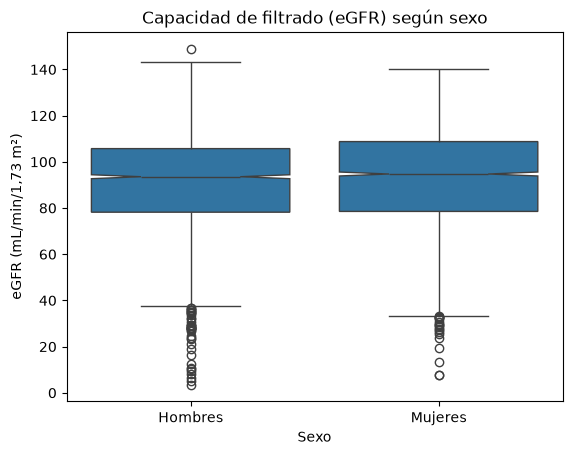

In [19]:
sns.boxplot(x="gender", y="egfr", data=adultos_con_egfr, order=["Male", "Female"], notch=True)
plt.title("Capacidad de filtrado (eGFR) según sexo")
plt.xlabel("Sexo")
plt.xticks(ticks=[0, 1], labels=["Hombres", "Mujeres"])
plt.ylabel("eGFR (mL/min/1,73 m²)")
plt.show()

Las dos cajas son muy parecidas: la mediana de las mujeres (94,7) es apenas mayor que la de los hombres (93,6), y los notches casi se superponen. A simple vista la diferencia es muy chica, así que verificaremos los supuestos de normalidad y homocedasticidad para elegir el test correcto y saber si es significativa. También se ven muchos outliers en la parte de abajo (personas con filtrado muy bajo); esto es un indicio de que la distribución no es simétrica.

### Supuesto 1: normalidad
Evaluamos la normalidad con el **test de Shapiro-Wilk**, cuya hipótesis nula es que los datos son normales: si el p-valor es menor a α, se rechaza la normalidad.

In [20]:
alpha = 0.05

stat, p = shapiro(egfr_hombres)
print(f"Test de Shapiro-Wilk para hombres: Estadístico={stat:.3f}, p-valor={p:.3e}")

stat, p = shapiro(egfr_mujeres)
print(f"Test de Shapiro-Wilk para mujeres: Estadístico={stat:.3f}, p-valor={p:.3e}")

Test de Shapiro-Wilk para hombres: Estadístico=0.983, p-valor=6.648e-17
Test de Shapiro-Wilk para mujeres: Estadístico=0.987, p-valor=4.541e-16


En los dos grupos el p-valor es menor a 0.05, así que **rechazamos la normalidad**.

Lo complementamos con un QQ plot por grupo. El eje X tiene los cuantiles de una distribución normal teórica y el eje Y los cuantiles de los datos. Si los puntos siguen la línea roja, los datos son normales; si se alejan, no lo son.

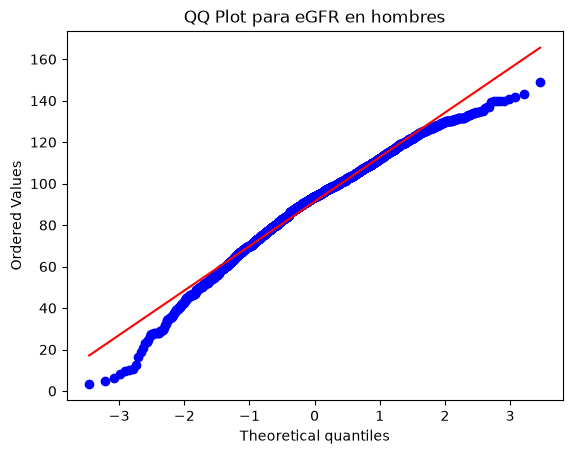

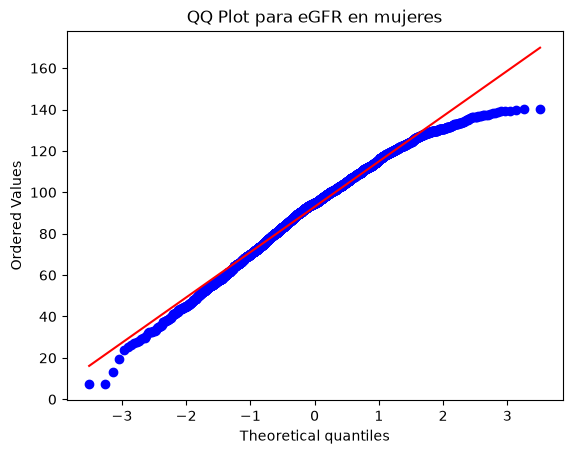

In [21]:
stats.probplot(egfr_hombres, dist="norm", plot=plt)
plt.title("QQ Plot para eGFR en hombres")
plt.show()

stats.probplot(egfr_mujeres, dist="norm", plot=plt)
plt.title("QQ Plot para eGFR en mujeres")
plt.show()

En los dos QQ plots los puntos se apartan de la línea en los extremos: abajo a la izquierda caen muy por debajo (personas con filtrado muy bajo, una cola larga hacia valores chicos) y arriba a la derecha quedan por debajo de la línea. Esto coincide con el resultado de Shapiro-Wilk: **eGFR no se distribuye normal en ningún grupo**.

### Supuesto 2: homocedasticidad

Evaluamos si las varianzas de `egfr` son iguales en los dos grupos con el **test de Levene**, que elegimos porque es más robusto que el test F de Fisher cuando los datos no son normales. Su hipótesis nula es que las varianzas son iguales.

In [22]:
stat, p = stats.levene(egfr_hombres, egfr_mujeres)
print(f"Test de Levene para eGFR: Estadístico={stat:.3f}, p-valor={p:.3f}")

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("Las varianzas de eGFR son iguales entre hombres y mujeres.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Las varianzas de eGFR son diferentes entre hombres y mujeres.")

Test de Levene para eGFR: Estadístico=4.955, p-valor=0.026
Se rechaza la hipótesis nula.
Las varianzas de eGFR son diferentes entre hombres y mujeres.


El p-valor es menor a 0.05, así que **no hay homocedasticidad**.

### Elección del test

Como no se cumple ninguno de los dos supuestos, usamos el **test de Kruskal-Wallis**, que no necesita normalidad ni varianzas iguales. Trabaja con los rangos de los datos (su posición al ordenarlos de menor a mayor) en lugar de con los valores, por eso también es robusto a los outliers que se vieron en el boxplot. Su hipótesis nula es que no hay diferencias entre los grupos.

In [23]:
stat, p = stats.kruskal(egfr_hombres, egfr_mujeres)
print(f"Test de Kruskal-Wallis para eGFR: Estadístico={stat:.3f}, p-valor={p:.4f}")

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la capacidad de filtrado entre hombres y mujeres.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la capacidad de filtrado entre hombres y mujeres.")

print(f"Mediana de eGFR en hombres: {egfr_hombres.median():.2f}")
print(f"Mediana de eGFR en mujeres: {egfr_mujeres.median():.2f}")

Test de Kruskal-Wallis para eGFR: Estadístico=7.992, p-valor=0.0047
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la capacidad de filtrado entre hombres y mujeres.
Mediana de eGFR en hombres: 93.56
Mediana de eGFR en mujeres: 94.73


### Conclusión

**Rechazamos H0: existen diferencias significativas en la capacidad de filtrado entre hombres y mujeres** (Kruskal-Wallis, p ≈ 0,005). Las mujeres tienen una mediana de eGFR levemente mayor (94,7) que la de los hombres (93,6).

Sin embargo, la diferencia es de solo 1,2 mL/min/1,73 m², muy chica desde el punto de vista clínico: no cambia la etapa renal de nadie (los cortes entre etapas están separados por 15 a 30 unidades). Con más de 5600 personas, el test es capaz de detectar diferencias muy pequeñas, por lo que el resultado es estadísticamente significativo pero de poca relevancia práctica, como también se veía en el boxplot.

La ecuación CKD-EPI 2021 usa el sexo para calcular el eGFR, para corregir que los hombres tienen más masa muscular y, por eso, más creatinina en sangre. La comparación muestra la diferencia que queda después de ese ajuste.

## Análisis de la hipótesis multivariada: existe un vínculo directo entre el eGFR, la relación albúmina/creatinina en orina, el ácido úrico, el fósforo, el bicarbonato y el BMI con la probabilidad de tener diabetes diagnosticada

### Planteo de la hipótesis

Según la metadata, la diabetes es uno de los factores más relacionados con el deterioro renal. Por eso planteamos esta hipótesis: queremos ver si los marcadores de la función renal y otros valores del análisis de sangre se relacionan con tener diabetes, junto con el BMI, que es una de las características más asociadas a esta enfermedad.

Como la variable a explicar es binaria (tiene diabetes / no tiene diabetes), usamos una **regresión logística**, que es el modelo que vimos para cuando la variable a explicar es binaria. El modelo estima la probabilidad de tener diabetes a partir de todas las variables juntas, así que el efecto de cada una queda ajustado por las demás.

Tomamos tres decisiones sobre las variables:
- **Agregamos la edad como variable de control.** Las personas con diabetes son mucho mayores que las que no tienen (mediana de 65 años contra 53), y el eGFR baja con la edad porque la edad forma parte de su fórmula. Si no la incluyéramos, podríamos atribuirle al eGFR un efecto que en realidad es de la edad. 
- **No incluimos `urine_albumin`**, porque ya está contenida en `albumin_creatinine_ratio` (el ACR es la albúmina en orina dividida por la creatinina en orina). Usar las dos sería repetir la misma información.
- **Usamos el BMI y no el peso**, porque el peso depende de la altura: una persona alta pesa más sin necesariamente tener sobrepeso. El BMI corrige eso.

Para cada variable planteamos:
- **H0:** la variable no tiene vínculo con la probabilidad de tener diabetes (su odds ratio es 1).
- **H1:** la variable tiene vínculo con la probabilidad de tener diabetes (su odds ratio es distinto de 1).
- **Nivel de significancia:** α = 0.05

### Variable objetivo y población

Creamos la variable `diabetes`, que vale **1** si la persona tiene diabetes diagnosticada (`diabetes_diagnosed` = 1) y **0** si no (2). A los casos *borderline* (3) los tomamos como 0, porque corresponden a prediabetes.

Trabajamos con los adultos (18 años o más), ya que estos son los que se hicieron análisis de sangre, y nos quedamos solo con las filas que tienen todas las variables completas.

In [24]:
data_diabetes = data[data["age"] >= 18].copy()
data_diabetes["diabetes"] = data_diabetes["diabetes_diagnosed"].map({1: 1, 2: 0, 3: 0})

variables_diabetes = ["egfr", "albumin_creatinine_ratio", "uric_acid", "phosphorus", "bicarbonate", "bmi", "age"]

datos_diabetes = data_diabetes[variables_diabetes + ["diabetes"]].dropna().astype(float)

print(f"Personas incluidas en el modelo: {len(datos_diabetes)}")
print(f"Con diabetes: {int(datos_diabetes['diabetes'].sum())} ({datos_diabetes['diabetes'].mean() * 100:.2f}%)")
print(f"Sin diabetes: {int((datos_diabetes['diabetes'] == 0).sum())}")

Personas incluidas en el modelo: 5476
Con diabetes: 727 (13.28%)
Sin diabetes: 4749


Quedan 5476 adultos, de los cuales 727 (13,28 %) tienen diabetes diagnosticada. Como el eGFR y los demás valores de sangre solo se miden a partir de los 12 años y la población es de adultos, todas las personas incluidas tienen 18 años o más.

### Análisis exploratorio: matriz de correlación

Antes de ajustar el modelo, graficamos la **matriz de correlación** con un mapa de calor. Los colores rojos indican correlación positiva y los azules, negativa. Nos sirve para ver qué variables se relacionan más con `diabetes` (última fila) y si hay variables muy correlacionadas entre sí.

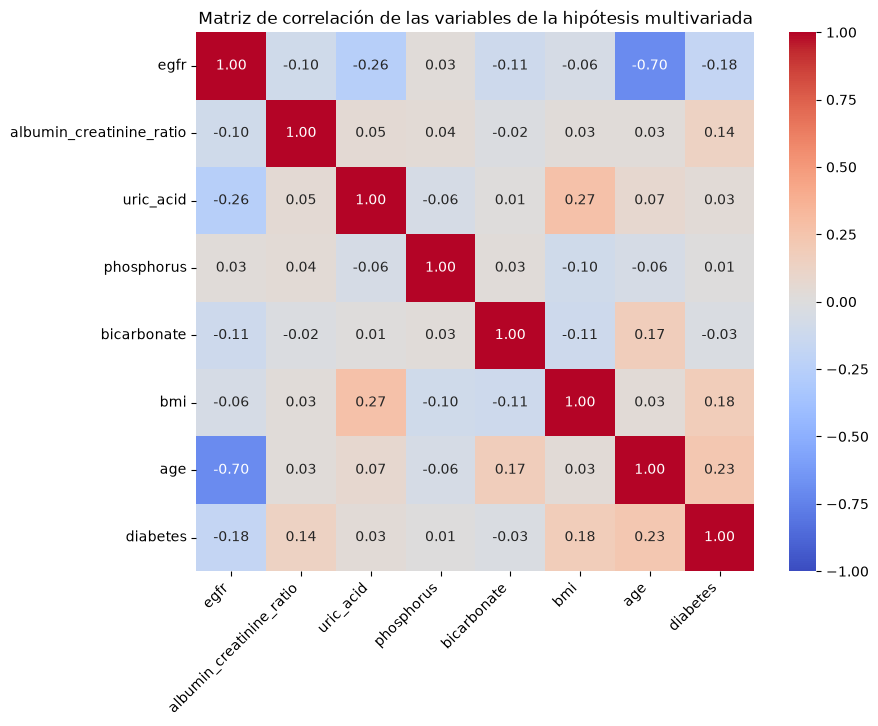

In [25]:
plt.figure(figsize=(9, 7))
sns.heatmap(datos_diabetes[variables_diabetes + ["diabetes"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de correlación de las variables de la hipótesis multivariada")
plt.xticks(rotation=45, ha="right")
plt.show()

Las variables más correlacionadas con `diabetes` son la edad (0,23), el BMI (0,18), el eGFR (-0,18, negativa: los diabéticos tienen el filtrado más bajo) y el ACR (0,14). El ácido úrico, el fósforo y el bicarbonato tienen correlaciones cercanas a 0.

Entre las variables predictoras, la correlación más fuerte es entre el eGFR y la edad (-0,70): como dijimos, el eGFR baja con los años. Por eso es importante tener a las dos en el modelo, para poder separar el efecto de cada una.

### Multicolinealidad: VIF

Uno de los supuestos de la regresión es que no haya **multicolinealidad**, es decir, que ninguna variable predictora se pueda explicar casi por completo con las demás. Si pasa, los coeficientes se vuelven inestables y sus p-valores dejan de ser confiables. Lo medimos con el **VIF** (factor de inflación de la varianza), como vimos en clase: un VIF cercano a 1 indica que no hay problema, y valores mayores a 5 nos dan sospechas de multicolinealidad.

In [26]:
X_vif_diabetes = sm.add_constant(datos_diabetes[variables_diabetes])

vif_diabetes = pd.DataFrame({
    "Variable": variables_diabetes,
    "VIF": [variance_inflation_factor(X_vif_diabetes.values, i + 1) for i in range(len(variables_diabetes))]
})
vif_diabetes.round(2)

,Variable,VIF
0,egfr,2.17
1,albumin_creatinine_ratio,1.02
2,uric_acid,1.19
3,phosphorus,1.02
4,bicarbonate,1.05
5,bmi,1.11
6,age,2.07


Todos los VIF están por debajo de 2,2, así que **no hay multicolinealidad**.

### Estandarización de las variables

Las variables están en unidades distintas (mL/min, mg/g, mg/dL, mmol/L, kg/m², años), así que las estandarizamos con `StandardScaler`. Así todas quedan con media 0 y desvío 1, y el efecto de cada una se mide "por cada desvío estándar" de esa variable.

In [27]:
scaler_diabetes = StandardScaler()
X_diabetes = pd.DataFrame(scaler_diabetes.fit_transform(datos_diabetes[variables_diabetes]),
                          columns=variables_diabetes, index=datos_diabetes.index)
X_diabetes = sm.add_constant(X_diabetes)
y_diabetes = datos_diabetes["diabetes"]


### Regresión logística

Ajustamos el modelo con `sm.Logit`. En el resumen, el p-valor de cada variable (`P>|z|`) indica si tiene un vínculo significativo con la diabetes: si es menor a 0.05, rechazamos H0.

In [28]:
modelo_diabetes = sm.Logit(y_diabetes, X_diabetes).fit()
print(modelo_diabetes.summary())

Optimization terminated successfully.
         Current function value: 0.333110
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:               diabetes   No. Observations:                 5476
Model:                          Logit   Df Residuals:                     5468
Method:                           MLE   Df Model:                            7
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.1494
Time:                        15:02:29   Log-Likelihood:                -1824.1
converged:                       True   LL-Null:                       -2144.4
Covariance Type:            nonrobust   LLR p-value:                4.361e-134
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -2.2649      0.055    -40.850      0.000      -2.374

El **LLR p-value** es prácticamente 0, así que el modelo en su conjunto es significativo. El **Pseudo R²** es 0,149: las variables explican una parte de la probabilidad de tener diabetes, aunque hay otros factores importantes que no están en el dataset (por ejemplo, la glucosa en sangre o los antecedentes familiares).

### Odds ratios

Los coeficientes en *log-odds* son difíciles de leer, así que los transformamos en **odds ratios** (OR) aplicando la exponencial (`np.exp`). El OR dice cuánto se multiplican las chances (*odds*) de tener diabetes cuando la variable aumenta un desvío estándar, con las demás variables fijas:
- **OR mayor a 1:** la variable aumenta las chances de tener diabetes.
- **OR menor a 1:** la variable las disminuye.
- **OR igual a 1:** no hay vínculo.

También calculamos el intervalo de confianza del 95 % de cada OR.

In [29]:
intervalos_diabetes = np.exp(modelo_diabetes.conf_int())

odds_ratios_diabetes = pd.DataFrame({
    "Odds ratio": np.exp(modelo_diabetes.params),
    "IC 95% inferior": intervalos_diabetes[0],
    "IC 95% superior": intervalos_diabetes[1],
    "p-valor": modelo_diabetes.pvalues,
    "Significativa": modelo_diabetes.pvalues < alpha
}).drop("const")

odds_ratios_diabetes.round(4)

,Odds ratio,IC 95% inferior,IC 95% superior,p-valor,Significativa
egfr,1.0115,0.8977,1.1397,0.8510,False
albumin_creatinine_ratio,2.4965,1.9578,3.1835,0.0000,True
uric_acid,0.8577,0.7817,0.9409,0.0012,True
phosphorus,1.1050,1.0140,1.2042,0.0228,True
bicarbonate,0.8503,0.7810,0.9257,0.0002,True
bmi,1.7704,1.6316,1.9210,0.0000,True
age,2.5559,2.2193,2.9436,0.0000,True


### Gráfico de los odds ratios

Graficamos los OR en un **gráfico de barras**, con el intervalo de confianza de cada uno como barra de error. La **línea roja punteada** marca el OR = 1, que es el valor de "sin vínculo". En azul están las variables significativas y en gris las que no lo son.

**Cómo se lee:** si la barra de error de una variable no toca la línea roja, el vínculo es significativo. Las barras que pasan la línea aumentan las chances de tener diabetes, y las que quedan por debajo, las disminuyen.

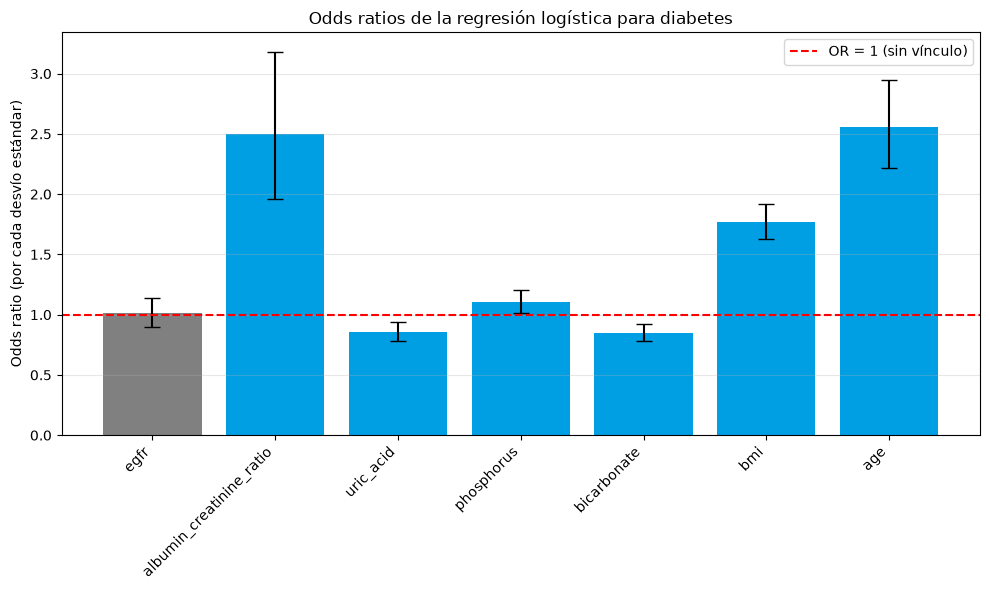

In [30]:
colores_diabetes = ["#009FE4" if significativa else "gray" for significativa in odds_ratios_diabetes["Significativa"]]
error_inferior = odds_ratios_diabetes["Odds ratio"] - odds_ratios_diabetes["IC 95% inferior"]
error_superior = odds_ratios_diabetes["IC 95% superior"] - odds_ratios_diabetes["Odds ratio"]

plt.figure(figsize=(10, 6))
plt.bar(odds_ratios_diabetes.index, odds_ratios_diabetes["Odds ratio"], color=colores_diabetes,
        yerr=[error_inferior, error_superior], capsize=6)
plt.axhline(1, color="red", linestyle="--", label="OR = 1 (sin vínculo)")
plt.ylabel("Odds ratio (por cada desvío estándar)")
plt.title("Odds ratios de la regresión logística para diabetes")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### ¿Por qué incluimos la edad?

Para mostrar por qué agregamos la edad como variable de control, ajustamos el mismo modelo sin ella y comparamos los resultados del eGFR.

In [31]:
variables_sin_edad = [variable for variable in variables_diabetes if variable != "age"]

X_sin_edad = pd.DataFrame(StandardScaler().fit_transform(datos_diabetes[variables_sin_edad]),
                          columns=variables_sin_edad, index=datos_diabetes.index)
X_sin_edad = sm.add_constant(X_sin_edad)

modelo_sin_edad = sm.Logit(y_diabetes, X_sin_edad).fit()

print(f"eGFR sin la edad en el modelo: OR={np.exp(modelo_sin_edad.params['egfr']):.4f}, p-valor={modelo_sin_edad.pvalues['egfr']:.4f}")
print(f"eGFR con la edad en el modelo: OR={np.exp(modelo_diabetes.params['egfr']):.4f}, p-valor={modelo_diabetes.pvalues['egfr']:.4f}")

Optimization terminated successfully.
         Current function value: 0.350733
         Iterations 7
eGFR sin la edad en el modelo: OR=0.5921, p-valor=0.0000
eGFR con la edad en el modelo: OR=1.0115, p-valor=0.8510


Sin la edad, el eGFR parece tener un vínculo fuerte con la diabetes (OR = 0,59, p < 0,001): los diabéticos tendrían el filtrado más bajo. Pero al agregar la edad, ese vínculo desaparece (OR = 1,01, p = 0,85). Esto muestra que la relación entre el eGFR y la diabetes se explicaba por la edad: los diabéticos tienen el filtrado más bajo porque son mayores, no por la diabetes en sí.

### Conclusión

**La hipótesis se confirma parcialmente.** Ajustando por la edad, encontramos un vínculo significativo con la probabilidad de tener diabetes en cinco de las seis variables:

| Variable | Odds ratio | p-valor | Interpretación (por cada desvío estándar) |
|---|---|---|---|
| BMI | 1,77 | < 0,001 | Cada 7 kg/m² más, las chances de tener diabetes aumentan un 77 % |
| ACR | 2,50 | < 0,001 | A mayor albuminuria, más chances de tener diabetes |
| Fósforo | 1,11 | 0,023 | Cada 0,5 mg/dL más, las chances aumentan un 11 % |
| Bicarbonato | 0,85 | < 0,001 | Cada 2,4 mmol/L más, las chances disminuyen un 15 % |
| Ácido úrico | 0,86 | 0,001 | Cada 1,4 mg/dL más, las chances disminuyen un 14 % |

En cambio, **el eGFR no tiene un vínculo significativo** con la diabetes una vez que se considera la edad (p = 0,85). Como vimos en el bloque anterior, la relación que aparecía sin la edad se debía a que los diabéticos son mayores.

El resultado más importante es que, de los dos marcadores renales, el que se asocia a la diabetes es la **albuminuria (ACR)** y no el filtrado (eGFR). Es coherente con lo que indica la metadata: la albúmina en orina puede señalar daño de la barrera de filtración del riñón, y ese daño puede aparecer antes de que baje el filtrado. El BMI fue, después del ACR, la variable con mayor efecto.

El ácido úrico da un OR menor a 1, lo que parece contradictorio porque se suele asociar a la obesidad. Hay que tener en cuenta que el modelo ya incluye el BMI (que está correlacionado con el ácido úrico): a igual BMI, los diabéticos tienen el ácido úrico algo más bajo. Una posible explicación es que la glucosa alta en la orina hace que el riñón elimine más ácido úrico, aunque con estos datos no podemos comprobarlo.

**Limitaciones:**
- La regresión muestra **asociaciones**, no causas. En particular, no podemos saber si la albuminuria aparece por la diabetes o al revés.
- La diabetes es **declarada** (si un médico se la diagnosticó). Las personas con diabetes no diagnosticada quedan contadas como no diabéticas, y el dataset no tiene la glucosa en sangre para detectarlas.

### Relación con el daño renal y la CKD

El modelo nos dice qué valores se asocian a la diabetes, pero el objetivo del trabajo es la enfermedad renal. Para conectar los dos resultados, comparamos cómo se reparten las etapas de CKD y cuántas personas tienen albuminuria (ACR de 30 mg/g o más) entre los adultos con diabetes y sin diabetes.

In [32]:
data_relacion = data[(data["age"] >= 18) & (data["ckd_stage"] != "Unknown")].copy()
data_relacion["grupo_diabetes"] = data_relacion["diabetes_diagnosed"].map({1: "Con diabetes", 2: "Sin diabetes", 3: "Sin diabetes"})
data_relacion["albuminuria"] = data_relacion["albumin_creatinine_ratio"] >= 30

print("Porcentaje de personas en cada etapa de CKD:")
print((pd.crosstab(data_relacion["grupo_diabetes"], data_relacion["ckd_stage"], normalize="index") * 100).round(1))
print()

con_acr = data_relacion.dropna(subset=["albumin_creatinine_ratio"])
print("Porcentaje de personas con albuminuria (ACR >= 30):")
print((con_acr.groupby("grupo_diabetes")["albuminuria"].mean() * 100).round(1))

Porcentaje de personas en cada etapa de CKD:
ckd_stage       No CKD  Stage1  Stage2  Stage3a  Stage3b  Stage4  Stage5
grupo_diabetes                                                          
Con diabetes      34.4    11.1    34.0     12.8      5.4     1.6     0.8
Sin diabetes      56.2     4.3    33.0      5.0      1.1     0.3     0.1

Porcentaje de personas con albuminuria (ACR >= 30):
grupo_diabetes
Con diabetes    32.0
Sin diabetes     8.3
Name: albuminuria, dtype: float64


Esta tabla nos ayuda a entender cómo se relaciona la diabetes con el daño renal:

- **La albuminuria es mucho más frecuente en los diabéticos:** el 32,0 % la tiene, contra el 8,3 % de los no diabéticos. Es el mismo resultado que dio el modelo (OR = 2,50 para el ACR). Según la metadata, la albúmina en la orina puede señalar daño en la barrera de filtración del riñón, así que la diabetes se asocia a un **daño renal que se puede detectar en la orina**, aunque el filtrado todavía sea normal.
- **Por eso los diabéticos están más en `Stage1`:** el 11,1 % de los diabéticos está en `Stage1` contra el 4,3 % de los no diabéticos. `Stage1` es justamente la etapa de "daño renal" con filtrado conservado (eGFR de 90 o más y ACR de 30 o más). Es la forma en que la diabetes afecta primero al riñón.
- **También están más en las etapas avanzadas:** de `Stage3a` a `Stage5` están el 20,6 % de los diabéticos, contra el 6,5 % de los no diabéticos.
- **En `Stage2` no hay diferencia:** 34,0 % contra 33,0 %. Según la metadata, `Stage2` se asigna solo por un eGFR levemente bajo (entre 60 y 89), que depende sobre todo de la edad.

Esto también ayuda a entender un resultado de la hipótesis 4c, que analizamos más adelante: allí la diabetes no tiene un vínculo significativo con `ckd_present`. La mayoría de los casos de `ckd_present` son `Stage2`, la única etapa donde diabéticos y no diabéticos están igual. La relación entre la diabetes y el riñón aparece en la albuminuria (`Stage1`) y en las etapas avanzadas, que son una parte chica de los casos, así que queda tapada dentro de `ckd_present`.

En resumen: **conocer la diabetes de una persona nos da información sobre su riesgo de daño renal**, en especial sobre la albuminuria, que es la primera señal del daño, antes de que baje el filtrado. Medir el ACR en las personas con diabetes permite detectar ese daño temprano.


## Hipótesis 4a: la mayoría de los casos de CKF identificados corresponde a blancos no hispánicos

### Planteo de la hipótesis

**CKF** (*Chronic Kidney Failure*, falla renal crónica) corresponde a la última etapa de la enfermedad renal crónica: `Stage5` (en el archivo original, `Stage 5 (Kidney Failure)`), con eGFR menor a 15 mL/min/1,73 m².

"La mayoría" significa que los blancos no hispánicos representan más del 50 % de los casos de CKF identificados.

Los registros con `ckd_stage` igual a `Unknown` no tienen eGFR, así que no se puede saber si alguno está en la etapa 5. La hipótesis habla de casos identificados, por lo que analizamos solo los que tienen la etapa 5 asignada. Al filtrar por esa etapa, los `Unknown` quedan afuera automáticamente.

### Casos de CKF identificados

In [33]:
casos_ckf = data[data["ckd_stage"] == "Stage5"]
total_casos_ckf = len(casos_ckf)

print(f"Total de casos de CKF identificados: {total_casos_ckf}")
print(f"Casos sin etnia registrada: {casos_ckf['ethnicity'].isna().sum()}")
casos_ckf[["participant_id", "age", "gender", "ethnicity", "egfr"]]

Total de casos de CKF identificados: 11
Casos sin etnia registrada: 0


,participant_id,age,gender,ethnicity,egfr
433,130811,59,Male,Other Hispanic,10.67
2382,132760,60,Male,Non-Hispanic Black,6.46
2397,132775,46,Female,Mexican American,7.57
5669,136047,80,Male,Non-Hispanic White,12.58
6251,136629,50,Male,Non-Hispanic Asian,3.51
6454,136832,72,Male,Non-Hispanic White,9.62
8290,138668,49,Male,Other Hispanic,4.96
10198,140576,80,Female,Non-Hispanic White,7.53
11386,141764,62,Male,Non-Hispanic White,8.28
11480,141858,69,Male,Other/Multiracial,10.24


In [34]:
conteo_etnias = casos_ckf["ethnicity"].value_counts()
porcentaje_etnias = casos_ckf["ethnicity"].value_counts(normalize=True) * 100

tabla_etnias = pd.DataFrame({"Casos": conteo_etnias, "Porcentaje (%)": porcentaje_etnias.round(2)})
tabla_etnias

,Casos,Porcentaje (%)
ethnicity,,
Non-Hispanic White,4,36.36
Other Hispanic,2,18.18
Mexican American,2,18.18
Non-Hispanic Black,1,9.09
Non-Hispanic Asian,1,9.09
Other/Multiracial,1,9.09


### Gráfico: casos de CKF por etnia

Usamos un gráfico de barras con el porcentaje de casos de cada grupo étnico. La línea roja punteada marca el 50 %: para que la hipótesis se cumpla, la barra de los blancos no hispánicos (en azul) tendría que superarla.

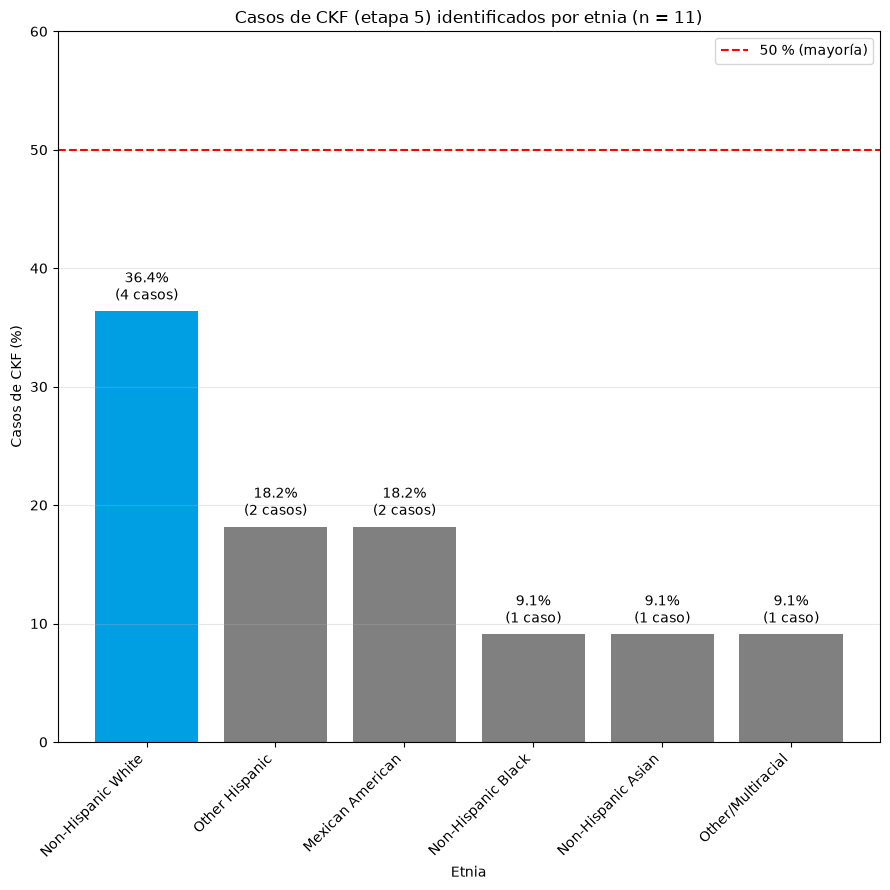

In [35]:
colores = ["#009FE4" if etnia == "Non-Hispanic White" else "gray" for etnia in porcentaje_etnias.index]

plt.figure(figsize=(9, 9))
plt.bar(porcentaje_etnias.index, porcentaje_etnias.values, color=colores)
plt.axhline(50, color="red", linestyle="--", label="50 % (mayoría)")

for i, etnia in enumerate(porcentaje_etnias.index):
    plt.text(i, porcentaje_etnias[etnia] + 1, f"{porcentaje_etnias[etnia]:.1f}%\n({conteo_etnias[etnia]} {'caso' if conteo_etnias[etnia] == 1 else 'casos'})", ha="center", fontsize=10)

plt.xlabel("Etnia")
plt.ylabel("Casos de CKF (%)")
plt.title(f"Casos de CKF (etapa 5) identificados por etnia (n = {total_casos_ckf})")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 60)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Por qué no aplicamos un test de hipótesis

- **Test t para una muestra:** la aproximación a la normal por el teorema central del límite necesita muestras grandes (n ≥ 30). Con 11 casos no se cumple.
- **Chi-cuadrado:** necesita que las frecuencias esperadas sean de al menos 5 por categoría. Con 11 casos repartidos en 6 etnias, la frecuencia esperada es de 11 / 6 ≈ 1,8, así que tampoco se cumple. Además, este test responde si las etnias tienen la misma cantidad de casos, que es una pregunta distinta a "la mayoría son blancos no hispánicos".

### Conclusión

**La hipótesis no se cumple.** De los 11 casos de CKF identificados, 4 corresponden a blancos no hispánicos (36,4 %). Aunque es el grupo con más casos, no llega a ser la mayoría: los otros 7 casos (63,6 %) se reparten entre las demás etnias.

**Limitaciones:**
- Con solo 11 casos, los porcentajes son muy inestables: un caso más o menos en un grupo cambia su porcentaje en unos 9 puntos. El resultado describe a esta muestra, pero no permite sacar conclusiones firmes sobre la población.
- A 5607 personas (`Unknown`) no se les midió la creatinina, así que no se sabe si alguna tiene CKF.

## Hipótesis 4b: la presión arterial es un factor de riesgo del CKF

### Planteo de la hipótesis

La presión arterial se mide con dos valores: la sistólica (`bp_systolic`, la presión máxima, cuando el corazón se contrae) y la diastólica (`bp_diastolic`, la presión mínima, entre latidos). Las dos forman parte de la presión arterial, así que las analizamos por separado, comparando cada una entre las personas con CKF y sin CKF. Cada comparación relaciona una variable con la presencia de CKF, por lo que la hipótesis es bivariada.

**Presión sistólica:**
- **H0:** no existen diferencias en la presión sistólica entre personas con CKF y sin CKF.
- **H1:** existen diferencias en la presión sistólica entre personas con CKF y sin CKF.

**Presión diastólica:**
- **H0:** no existen diferencias en la presión diastólica entre personas con CKF y sin CKF.
- **H1:** existen diferencias en la presión diastólica entre personas con CKF y sin CKF.

**Nivel de significancia:** α = 0.05

### Población y grupos

Trabajamos con los adultos evaluados: mayores de 18 años con eGFR calculado (los `Unknown` quedan afuera, porque no se sabe si tienen CKF) y con la presión arterial medida.

- **Grupo CKF:** personas en `Stage5`.
- **Grupo sin CKF:** el resto de los adultos evaluados (`No CKD` y `Stage1` a `Stage4`).

In [36]:
adultos_evaluados = data[(data["egfr"].notna()) & (data["age"] >= 18)].copy()
adultos_evaluados = adultos_evaluados.dropna(subset=["bp_systolic", "bp_diastolic"])

adultos_evaluados["grupo_ckf"] = ["CKF" if etapa == "Stage5" else "Sin CKF" for etapa in adultos_evaluados["ckd_stage"]]

con_ckf = adultos_evaluados[adultos_evaluados["grupo_ckf"] == "CKF"]
sin_ckf = adultos_evaluados[adultos_evaluados["grupo_ckf"] == "Sin CKF"]

print(f"Adultos evaluados con presión medida: {len(adultos_evaluados)}")
print(f"Con CKF: {len(con_ckf)}")
print(f"Sin CKF: {len(sin_ckf)}")


Adultos evaluados con presión medida: 5484
Con CKF: 11
Sin CKF: 5473


Como el grupo con CKF tiene solo 11 personas, mostramos sus valores uno por uno:

In [37]:
con_ckf[["age", "gender", "bp_systolic", "bp_diastolic", "egfr"]]

,age,gender,bp_systolic,bp_diastolic,egfr
433,59,Male,131,70,10.67
2382,60,Male,232,116,6.46
2397,46,Female,80,45,7.57
5669,80,Male,150,64,12.58
6251,50,Male,139,71,3.51
6454,72,Male,116,50,9.62
8290,49,Male,178,94,4.96
10198,80,Female,197,62,7.53
11386,62,Male,157,65,8.28
11480,69,Male,139,81,10.24


### Análisis gráfico de la hipótesis

Graficamos un boxplot de cada presión para los dos grupos. Como el grupo CKF tiene pocos casos, encima de su caja dibujamos cada persona como un punto rojo con `sns.stripplot`, que grafica cada observación individual. Así podemos ver si la caja está influida por algún valor extremo.

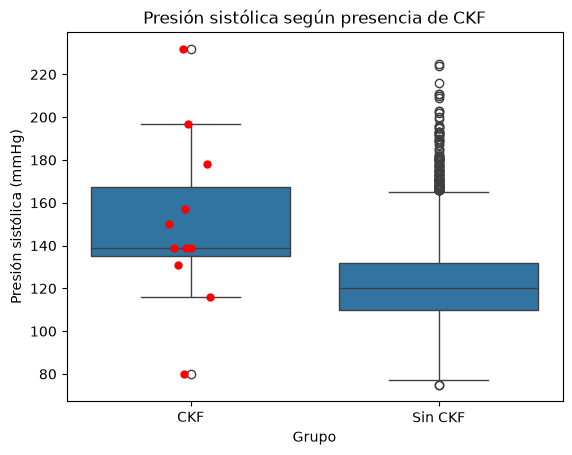

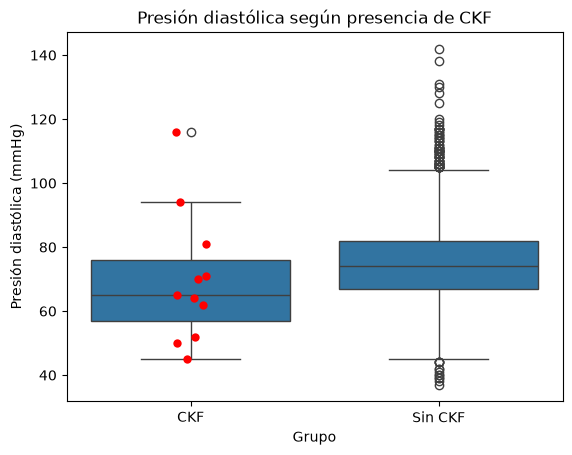

In [38]:
orden_grupos = ["CKF", "Sin CKF"]

sns.boxplot(x="grupo_ckf", y="bp_systolic", data=adultos_evaluados, order=orden_grupos)
sns.stripplot(x="grupo_ckf", y="bp_systolic", data=con_ckf, order=orden_grupos, color="red", size=6)
plt.title("Presión sistólica según presencia de CKF")
plt.xlabel("Grupo")
plt.ylabel("Presión sistólica (mmHg)")
plt.show()

sns.boxplot(x="grupo_ckf", y="bp_diastolic", data=adultos_evaluados, order=orden_grupos)
sns.stripplot(x="grupo_ckf", y="bp_diastolic", data=con_ckf, order=orden_grupos, color="red", size=6)
plt.title("Presión diastólica según presencia de CKF")
plt.xlabel("Grupo")
plt.ylabel("Presión diastólica (mmHg)")
plt.show()

En la **sistólica**, la caja del grupo CKF está claramente más arriba: su mediana es 139 mmHg contra 120 del grupo sin CKF, y la mayoría de sus puntos están por encima de la caja del otro grupo. En la **diastólica** pasa lo contrario: la mediana del grupo CKF (65 mmHg) es menor que la del grupo sin CKF (74 mmHg), con mucha dispersión. En los dos gráficos se ven casos extremos dentro del grupo CKF (por ejemplo, una persona con 232/116 y otra con 80/45), que con tan pocos datos pesan mucho.

### Supuesto 1: normalidad

Evaluamos la normalidad con el **test de Shapiro-Wilk** para cada grupo y cada presión (H0: los datos son normales).

- **Grupo CKF:** con solo 11 datos, el test tiene muy poca potencia: que no se rechace no prueba que sean normales, por eso es importante mirar también el QQ plot.

In [39]:
alpha = 0.05

stat, p = shapiro(con_ckf["bp_systolic"])
print(f"Test de Shapiro-Wilk para presión sistólica con CKF: Estadístico={stat:.3f}, p-valor={p:.3f}")

stat, p = shapiro(sin_ckf["bp_systolic"])
print(f"Test de Shapiro-Wilk para presión sistólica sin CKF: Estadístico={stat:.3f}, p-valor={p:.3e}")

stat, p = shapiro(con_ckf["bp_diastolic"])
print(f"Test de Shapiro-Wilk para presión diastólica con CKF: Estadístico={stat:.3f}, p-valor={p:.3f}")

stat, p = shapiro(sin_ckf["bp_diastolic"])
print(f"Test de Shapiro-Wilk para presión diastólica sin CKF: Estadístico={stat:.3f}, p-valor={p:.3e}")

Test de Shapiro-Wilk para presión sistólica con CKF: Estadístico=0.959, p-valor=0.759
Test de Shapiro-Wilk para presión sistólica sin CKF: Estadístico=0.960, p-valor=2.117e-36
Test de Shapiro-Wilk para presión diastólica con CKF: Estadístico=0.914, p-valor=0.273
Test de Shapiro-Wilk para presión diastólica sin CKF: Estadístico=0.983, p-valor=4.345e-25


/home/franco/Fundamentos/TPE/lib64/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5473.
  res = hypotest_fun_out(*samples, **kwds)
/home/franco/Fundamentos/TPE/lib64/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5473.
  res = hypotest_fun_out(*samples, **kwds)


En el grupo **sin CKF** rechazamos la normalidad en las dos presiones. En el grupo **CKF** no la rechazamos, pero por lo explicado arriba eso no alcanza para asumirla. Como basta con que un grupo no sea normal para no poder usar el test t, no se cumple el supuesto de normalidad.

Complementamos con los QQ plots de cada grupo:

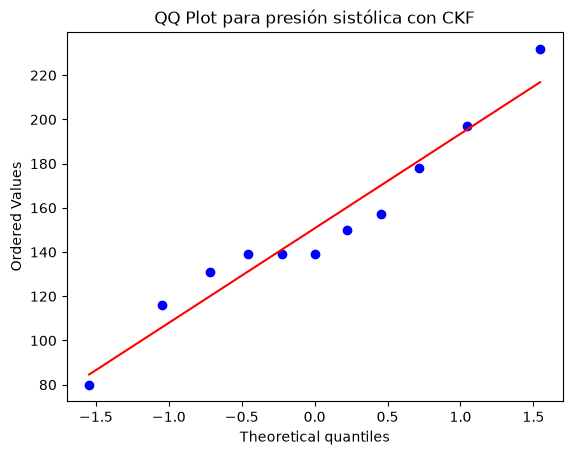

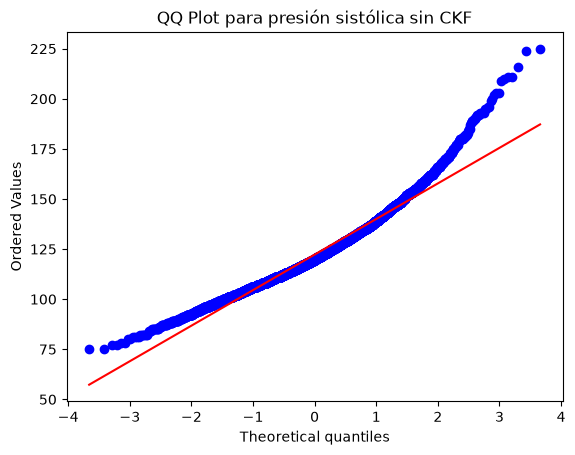

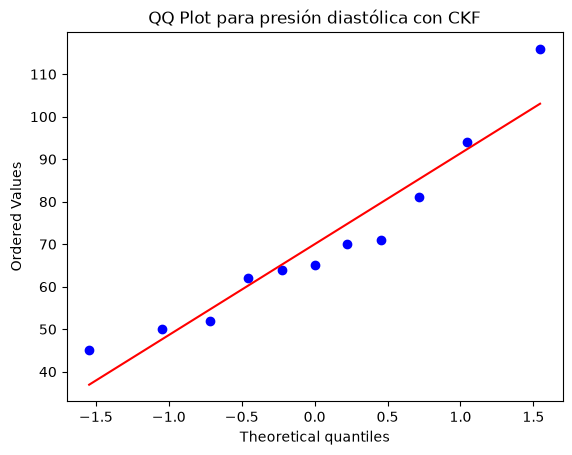

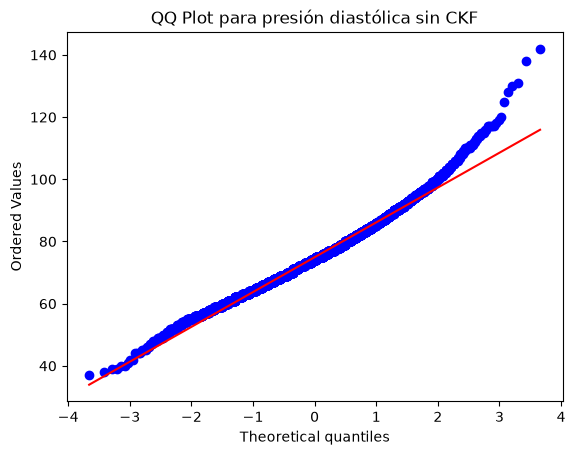

In [40]:
stats.probplot(con_ckf["bp_systolic"], dist="norm", plot=plt)
plt.title("QQ Plot para presión sistólica con CKF")
plt.show()

stats.probplot(sin_ckf["bp_systolic"], dist="norm", plot=plt)
plt.title("QQ Plot para presión sistólica sin CKF")
plt.show()

stats.probplot(con_ckf["bp_diastolic"], dist="norm", plot=plt)
plt.title("QQ Plot para presión diastólica con CKF")
plt.show()

stats.probplot(sin_ckf["bp_diastolic"], dist="norm", plot=plt)
plt.title("QQ Plot para presión diastólica sin CKF")
plt.show()

En el grupo **sin CKF**, los puntos se curvan por encima de la línea en el extremo derecho: hay una cola larga hacia valores altos de presión (asimetría a derecha), lo que confirma que no es normal. En el grupo **CKF** los 11 puntos están cerca de la línea, salvo los casos extremos en las puntas, pero con tan pocos puntos el gráfico no permite asegurar la normalidad.

### Supuesto 2: homocedasticidad

Evaluamos la homocedasticidad con el **test de Levene** (H0: las varianzas son iguales) para cada presión.

In [41]:
stat, p = stats.levene(con_ckf["bp_systolic"], sin_ckf["bp_systolic"])
print(f"Test de Levene para presión sistólica: Estadístico={stat:.3f}, p-valor={p:.3f}")

stat, p = stats.levene(con_ckf["bp_diastolic"], sin_ckf["bp_diastolic"])
print(f"Test de Levene para presión diastólica: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para presión sistólica: Estadístico=15.547, p-valor=0.000
Test de Levene para presión diastólica: Estadístico=6.848, p-valor=0.009


En las dos presiones el p-valor es menor a 0.05, así que **no hay homocedasticidad**: la presión varía mucho más en el grupo CKF que en el grupo sin CKF, como se veía en los boxplots.

### Elección del test

No se cumple ninguno de los dos supuestos, así que usamos el **test de Kruskal-Wallis** para cada presión. Como trabaja con los rangos de los datos y no con sus valores, no necesita normalidad, es robusto a los valores extremos y sirve para grupos chicos como el de CKF.

In [42]:
stat, p = stats.kruskal(con_ckf["bp_systolic"], sin_ckf["bp_systolic"])
print(f"Test de Kruskal-Wallis para presión sistólica: Estadístico={stat:.3f}, p-valor={p:.4f}")
print(f"Mediana con CKF: {con_ckf['bp_systolic'].median():.1f} mmHg | Mediana sin CKF: {sin_ckf['bp_systolic'].median():.1f} mmHg")

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la presión sistólica entre personas con y sin CKF.\n")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la presión sistólica entre personas con y sin CKF.\n")

stat, p = stats.kruskal(con_ckf["bp_diastolic"], sin_ckf["bp_diastolic"])
print(f"Test de Kruskal-Wallis para presión diastólica: Estadístico={stat:.3f}, p-valor={p:.4f}")
print(f"Mediana con CKF: {con_ckf['bp_diastolic'].median():.1f} mmHg | Mediana sin CKF: {sin_ckf['bp_diastolic'].median():.1f} mmHg")

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la presión diastólica entre personas con y sin CKF.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la presión diastólica entre personas con y sin CKF.")

Test de Kruskal-Wallis para presión sistólica: Estadístico=10.044, p-valor=0.0015
Mediana con CKF: 139.0 mmHg | Mediana sin CKF: 120.0 mmHg
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la presión sistólica entre personas con y sin CKF.

Test de Kruskal-Wallis para presión diastólica: Estadístico=2.887, p-valor=0.0893
Mediana con CKF: 65.0 mmHg | Mediana sin CKF: 74.0 mmHg
No hay suficiente evidencia para rechazar la hipótesis nula.
No hay una diferencia significativa en la presión diastólica entre personas con y sin CKF.


### Conclusión

**La hipótesis se confirma parcialmente.**

- **Presión sistólica:** rechazamos H0 (p ≈ 0,002). Las personas con CKF tienen la presión sistólica significativamente más alta (mediana de 139 mmHg contra 120 mmHg). Además, 9 de los 11 casos tienen una sistólica de 130 mmHg o más, valor a partir del cual se considera hipertensión.
- **Presión diastólica:** no rechazamos H0 (p ≈ 0,09). No hay evidencia de diferencias; de hecho, la mediana del grupo CKF es algo menor (65 contra 74 mmHg).

Que la sistólica esté alta y la diastólica baja podría deberse a que en el grupo con CKF la mediana de edad es de 62 años, contra 56 años en el grupo sin CKF: con la edad y la enfermedad renal, las arterias se vuelven más rígidas, lo que provoca que la presión sistólica suba y la diastólica baje.

**Limitaciones:**
- Con solo 11 casos de CKF, el análisis tiene poca potencia: que la diastólica no dé significativa no prueba que no haya diferencia, y uno o dos casos extremos pueden mover mucho el resultado.
- El resultado muestra una asociación, no que la presión cause el CKF. La relación puede ir en los dos sentidos: la hipertensión daña el riñón y la enfermedad renal también eleva la presión.
- La edad influye tanto en la presión como en la función renal, así que parte de la diferencia puede deberse a la edad. Este efecto lo podemos controlar en un análisis multivariado, como el de la hipótesis 4c.
- El dataset no informa si las personas toman medicación para la presión o están en diálisis, dos tratamientos habituales en el CKF que modifican la presión medida el día del examen.

## Hipótesis 4c: existe un vínculo directo entre la edad, el sexo, el BMI, la presión arterial, la diabetes, el tabaquismo y el nivel socioeconómico con la probabilidad de presentar CKD

### Planteo de la hipótesis

Utilizamos **regresión logística**, que es el modelo que vimos para cuando la variable a explicar es binaria (tiene CKD / no tiene CKD). El modelo estima la probabilidad de presentar CKD a partir de todos los factores juntos.

La ventaja de meter todas las variables en un mismo modelo es que el efecto de cada una queda ajustado por las demás. Por ejemplo, si la presión parece relacionada con la CKD solo porque las personas mayores tienen la presión más alta, el modelo lo separa, porque la edad también está incluida.

Para cada variable planteamos:
- **H0:** la variable no tiene vínculo con la probabilidad de presentar CKD (su coeficiente es 0, o su odds ratio es 1).
- **H1:** la variable tiene vínculo con la probabilidad de presentar CKD (su coeficiente es distinto de 0).
- **Nivel de significancia:** α = 0.05

La hipótesis completa se cumpliría si todas las variables tuvieran un vínculo significativo.

### Variable objetivo

Como variable a explicar usamos `ckd_present`, que indica si la persona tiene CKD diagnosticada según `ckd_stage`:
- **1 (tiene CKD):** personas en `Stage1` a `Stage5`.
- **0 (no tiene CKD):** personas en `No CKD`.

Igual que en las hipótesis anteriores, dejamos afuera los `Unknown`. Según la metadata, en `ckd_present` vienen codificados como 1, pero en realidad no tienen eGFR calculado, así que no sabemos si tienen CKD. Si los dejáramos, contaríamos como enfermas a 5607 personas sin diagnóstico.

Con una tabla cruzada (`pd.crosstab`) verificamos que, sin los `Unknown`, `ckd_present` coincide con la etapa de `ckd_stage`.

In [43]:
data_4c = data[data["ckd_stage"] != "Unknown"].copy()

pd.crosstab(data_4c["ckd_stage"], data_4c["ckd_present"])

ckd_present,0,1
ckd_stage,,
No CKD,3592,0
Stage1,0,382
Stage2,0,1875
Stage3a,0,341
Stage3b,0,97
Stage4,0,28
Stage5,0,11


### Preparación de las variables

Pasamos las variables categóricas a 0 y 1 para poder usarlas en el modelo:
- `sexo_masculino`: 1 si es hombre y 0 si es mujer.
- `diabetes`: 1 si tiene diabetes diagnosticada (1) y 0 si no (2). A los casos *borderline* (3) los tomamos como 0, porque corresponden a prediabetes y no a diabetes diagnosticada.
- `fumo_alguna_vez`: 1 si fumó al menos 100 cigarrillos en su vida y 0 si no. Elegimos `ever_smoked` y no `current_smoker`, ya que tomamos a las personas que fumaron alguna vez más de 100 cigarrillos.

Las variables numéricas (edad, BMI, presiones, ratio de pobreza y nivel educativo) las dejamos como están. Al nivel educativo lo usamos como numérico porque sus categorías tienen un orden.

Después nos quedamos solo con las filas que tienen todas las variables completas, porque la regresión no admite valores faltantes.

In [44]:
data_4c["sexo_masculino"] = (data_4c["gender"] == "Male").astype(int)
data_4c["diabetes"] = data_4c["diabetes_diagnosed"].map({1: 1, 2: 0, 3: 0})
data_4c["fumo_alguna_vez"] = data_4c["ever_smoked"].map({1: 1, 2: 0})

variables = ["age", "sexo_masculino", "bmi", "bp_systolic", "bp_diastolic",
             "diabetes", "fumo_alguna_vez", "poverty_income_ratio", "education_level"]

datos_modelo = data_4c[variables + ["ckd_present"]].dropna().astype(float)

print(f"Personas incluidas en el modelo: {len(datos_modelo)}")
print(f"Edad mínima: {datos_modelo['age'].min():.0f} años")
print(f"Con CKD: {int(datos_modelo['ckd_present'].sum())} ({datos_modelo['ckd_present'].mean() * 100:.2f}%)")
print(f"Sin CKD: {int((datos_modelo['ckd_present'] == 0).sum())}")

Personas incluidas en el modelo: 4560
Edad mínima: 20 años
Con CKD: 2196 (48.16%)
Sin CKD: 2364


Quedan 4560 personas, todas de **20 años o más**. Esto pasa porque `education_level` solo se pregunta a partir de esa edad, así que al eliminar los faltantes quedan afuera los más jóvenes. El 48,16 % tiene CKD (2196 personas) y el resto no (2364).

### Análisis exploratorio: matriz de correlación

Antes de ajustar el modelo, graficamos la **matriz de correlación** con un mapa de calor. Los colores rojos indican correlación positiva y los azules, negativa. Nos sirve para ver qué variables se relacionan más con `ckd_present` y así analizar las correlaciones antes de la regresión.

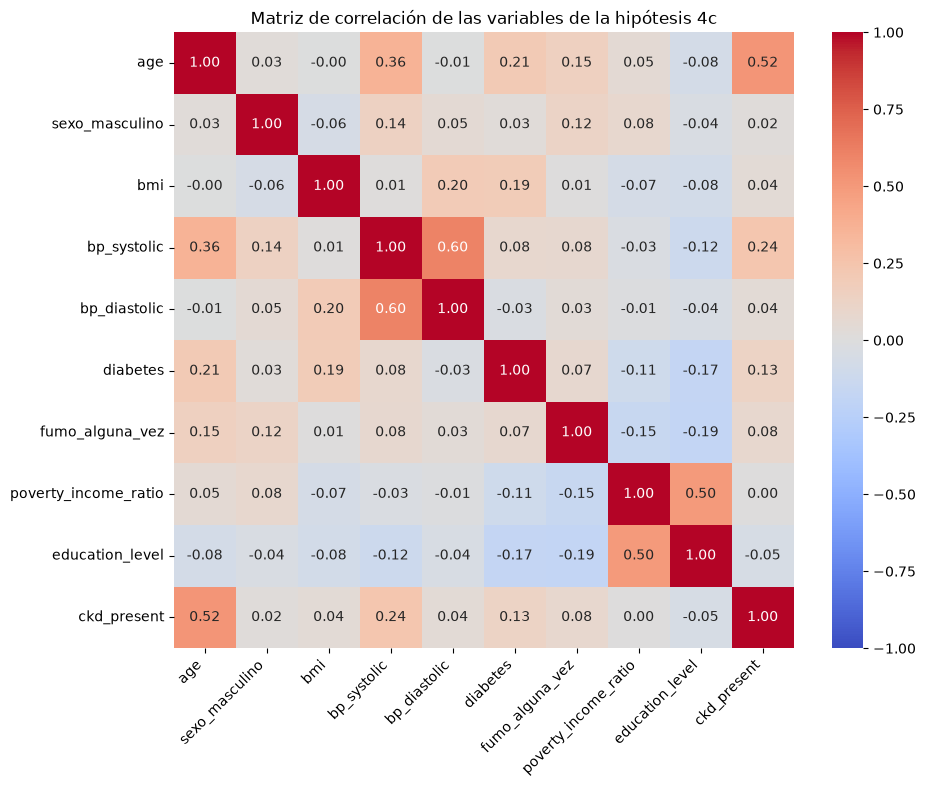

In [45]:
plt.figure(figsize=(10, 8))
sns.heatmap(datos_modelo[variables + ["ckd_present"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de correlación de las variables de la hipótesis 4c")
plt.xticks(rotation=45, ha="right")
plt.show()

La variable más correlacionada con `ckd_present` es, por lejos, la edad (0,52), seguida por la presión sistólica (0,24) y la diabetes (0,13). El resto tiene correlaciones muy bajas, cercanas a 0: el BMI (0,04), la presión diastólica (0,04), el tabaquismo (0,08), el sexo (0,02), el ratio de pobreza (0,00) y el nivel educativo (-0,05).

Entre las variables predictoras, las correlaciones más altas son entre la presión sistólica y la diastólica (0,60) y entre el ratio de pobreza y el nivel educativo (0,50).

Estas correlaciones miran cada variable por separado; el modelo de regresión, en cambio, las considera todas juntas.

### Multicolinealidad: VIF

Uno de los supuestos de la regresión es que no haya **multicolinealidad**, es decir, que ninguna variable predictora se pueda explicar casi por completo con las demás. Si pasa, los coeficientes se vuelven inestables y sus p-valores dejan de ser confiables. Lo medimos con el **VIF** (factor de inflación de la varianza), como vimos en clase: un VIF cercano a 1 indica que no hay problema, y valores mayores a 5 nos dan sospechas de multicolinealidad.

In [46]:
X_vif = sm.add_constant(datos_modelo[variables])

vif = pd.DataFrame({
    "Variable": variables,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(variables))]
})
vif.round(2)

,Variable,VIF
0,age,1.35
1,sexo_masculino,1.06
2,bmi,1.12
3,bp_systolic,2.09
4,bp_diastolic,1.86
5,diabetes,1.12
6,fumo_alguna_vez,1.08
7,poverty_income_ratio,1.38
8,education_level,1.40


Todos los VIF están por debajo de 2,1, así que **no hay multicolinealidad**. Podemos incluir la presión sistólica y la diastólica juntas, y también el ratio de pobreza y el nivel educativo, aunque estén algo correlacionadas.


### Estandarización de las variables

Las variables están en unidades distintas (años, mmHg, kg/m², 0 o 1), así que los coeficientes no se podrían comparar entre sí. Por eso las estandarizamos. Así todas quedan con media 0 y desvío 1, y el efecto de cada una se mide "por cada desvío estándar" de esa variable.

In [47]:
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(datos_modelo[variables]), columns=variables, index=datos_modelo.index)
X = sm.add_constant(X)
y = datos_modelo["ckd_present"]

pd.DataFrame({"Media": scaler.mean_, "Desvío estándar": scaler.scale_}, index=variables).round(2)


,Media,Desvío estándar
age,53.98,16.81
sexo_masculino,0.45,0.50
bmi,29.74,7.06
bp_systolic,122.81,18.18
bp_diastolic,75.44,11.19
diabetes,0.14,0.34
fumo_alguna_vez,0.42,0.49
poverty_income_ratio,3.00,1.64
education_level,3.91,1.11


In [48]:
modelo_logit = sm.Logit(y, X).fit()
print(modelo_logit.summary())

Optimization terminated successfully.
         Current function value: 0.538201
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            ckd_present   No. Observations:                 4560
Model:                          Logit   Df Residuals:                     4550
Method:                           MLE   Df Model:                            9
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.2228
Time:                        15:02:32   Log-Likelihood:                -2454.2
converged:                       True   LL-Null:                       -3157.7
Covariance Type:            nonrobust   LLR p-value:                2.477e-297
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.1509      0.036     -4.236      0.000      -0.221      -0.081

### Odds ratios

Los coeficientes en *log-odds* son difíciles de leer, así que los transformamos en **odds ratios** (OR) aplicando la exponencial (`np.exp`). El OR dice cuánto se multiplican las chances (*odds*) de tener CKD cuando la variable aumenta un desvío estándar, con las demás variables fijas:
- **OR mayor a 1:** la variable aumenta las chances de tener CKD (factor de riesgo).
- **OR menor a 1:** la variable las disminuye (factor protector).
- **OR igual a 1:** no hay vínculo.

También calculamos el intervalo de confianza del 95 % de cada OR.

In [49]:
intervalos = np.exp(modelo_logit.conf_int())

odds_ratios = pd.DataFrame({
    "Odds ratio": np.exp(modelo_logit.params),
    "IC 95% inferior": intervalos[0],
    "IC 95% superior": intervalos[1],
    "p-valor": modelo_logit.pvalues,
    "Significativa": modelo_logit.pvalues < alpha
}).drop("const")

odds_ratios.round(4)

,Odds ratio,IC 95% inferior,IC 95% superior,p-valor,Significativa
age,3.5583,3.2442,3.9028,0.0000,True
sexo_masculino,0.9945,0.9272,1.0666,0.8763,False
bmi,1.1202,1.0425,1.2036,0.0020,True
bp_systolic,1.1358,1.0263,1.2570,0.0138,True
bp_diastolic,1.0509,0.9552,1.1561,0.3084,False
diabetes,1.0388,0.9689,1.1138,0.2844,False
fumo_alguna_vez,1.0114,0.9426,1.0851,0.7530,False
poverty_income_ratio,0.9522,0.8790,1.0315,0.2303,False
education_level,1.0287,0.9491,1.1149,0.4913,False


Como estandarizamos las variables, para el modelo "aumentar 1" significa **aumentar un desvío estándar** de esa variable, y no una unidad (un año, un mmHg, etc.). Por eso los odds ratios de la tabla anterior son **por cada desvío estándar**. La tabla de la estandarización nos dice cuánto vale un desvío de cada variable.

In [50]:
or_por_unidad = pd.DataFrame({
    "Unidad": ["1 año", "mujer → hombre", "1 kg/m²", "1 mmHg", "1 mmHg", "no → sí", "no → sí", "1 punto", "1 nivel"],
    "Desvío estándar": scaler.scale_,
    "Coeficiente": modelo_logit.params[variables],
    "OR por desvío": np.exp(modelo_logit.params[variables]),
    "OR por unidad": np.exp(modelo_logit.params[variables] / scaler.scale_)
}, index=variables)

or_por_unidad.round(4)

,Unidad,Desvío estándar,Coeficiente,OR por desvío,OR por unidad
age,1 año,16.8143,1.2693,3.5583,1.0784
sexo_masculino,mujer → hombre,0.4976,-0.0056,0.9945,0.9889
bmi,1 kg/m²,7.0613,0.1135,1.1202,1.0162
bp_systolic,1 mmHg,18.1754,0.1274,1.1358,1.0070
bp_diastolic,1 mmHg,11.1935,0.0496,1.0509,1.0044
diabetes,no → sí,0.3444,0.0381,1.0388,1.1169
fumo_alguna_vez,no → sí,0.4931,0.0113,1.0114,1.0232
poverty_income_ratio,1 punto,1.6403,-0.0490,0.9522,0.9706
education_level,1 nivel,1.1072,0.0283,1.0287,1.0259


Para las tres variables significativas:
- **Edad:** cada año más, las chances de tener CKD se multiplican por 1,078 (aumentan un 7,8 %).
- **Presión sistólica:** cada mmHg más, las chances se multiplican por 1,007 (aumentan un 0,7 %). Es poco por cada mmHg, pero se acumula: cada 10 mmHg más, aumentan alrededor de un 7 %.
- **BMI:** cada kg/m² más, las chances se multiplican por 1,016 (aumentan un 1,6 %).

Las demás variables no son significativas, así que su OR por unidad no se interpreta.

### Gráfico de los odds ratios

Graficamos los OR en un **gráfico de barras**, con el intervalo de confianza de cada uno como barra de error. La **línea roja punteada** marca el OR = 1, que es el valor de "sin vínculo". En azul están las variables significativas y en gris las que no lo son (usamos la misma estructura para los colores que en la hipótesis 4a).

**Cómo se lee:** si la barra de error de una variable no toca la línea roja, el vínculo es significativo. Las barras que pasan la línea son factores de riesgo, y las que quedan por debajo, factores protectores.

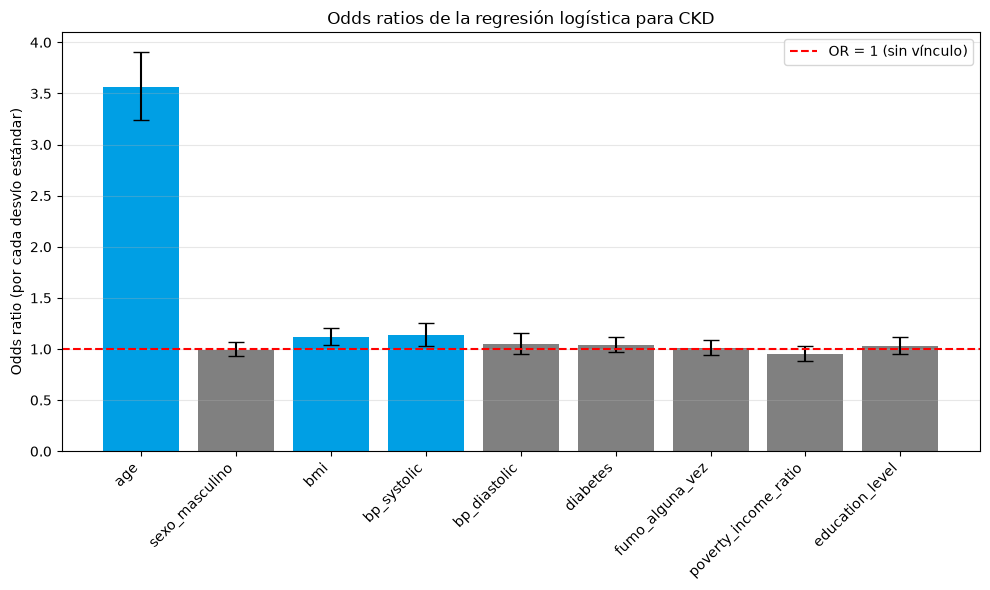

In [51]:
colores = ["#009FE4" if significativa else "gray" for significativa in odds_ratios["Significativa"]]
error_inferior = odds_ratios["Odds ratio"] - odds_ratios["IC 95% inferior"]
error_superior = odds_ratios["IC 95% superior"] - odds_ratios["Odds ratio"]

plt.figure(figsize=(10, 6))
plt.bar(odds_ratios.index, odds_ratios["Odds ratio"], color=colores,
        yerr=[error_inferior, error_superior], capsize=6)
plt.axhline(1, color="red", linestyle="--", label="OR = 1 (sin vínculo)")
plt.ylabel("Odds ratio (por cada desvío estándar)")
plt.title("Odds ratios de la regresión logística para CKD")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusión

**La hipótesis se confirma parcialmente.** Al considerar todos los factores juntos, encontramos un vínculo significativo con la probabilidad de presentar CKD en:

| Factor | OR por desvío | OR por unidad | p-valor | Interpretación |
|---|---|---|---|---|
| Edad | 3,56 | 1,078 | < 0,001 | Cada año más, las chances de tener CKD aumentan un 7,8 % (cada 17 años, se multiplican por 3,6) |
| Presión sistólica | 1,14 | 1,007 | 0,014 | Cada mmHg más, las chances aumentan un 0,7 % (cada 18 mmHg, un 14 %) |
| BMI | 1,12 | 1,016 | 0,002 | Cada kg/m² más, las chances aumentan un 1,6 % (cada 7 kg/m², un 12 %) |

En cambio, **no encontramos un vínculo significativo** con:
- **Sexo** (p = 0,88): hombres y mujeres tienen chances similares una vez que se consideran los demás factores.
- **Presión diastólica** (p = 0,31): como en la hipótesis 4b, lo que se asocia a la enfermedad renal es la presión sistólica. Además, una vez incluida la sistólica, la diastólica casi no agrega información nueva.
- **Diabetes** (p = 0,28).
- **Tabaquismo** (p = 0,75).
- **Nivel socioeconómico:** ni el ratio de pobreza (p = 0,23) ni el nivel educativo (p = 0,49).

En resumen, de los siete factores, solo la edad, el BMI y la presión arterial (a través de la sistólica) tienen un vínculo con la probabilidad de presentar CKD. La edad es, por lejos, el factor con más peso.

**Observaciones:**
- Según la metadata, `Stage2` se asigna solo por tener un eGFR entre 60 y 89, y el eGFR se calcula a partir de la edad. Por eso las personas con CKD son mucho mayores (mediana de 65 años contra 44 de las que no tienen), y la edad concentra gran parte del efecto, lo que puede hacer más difícil detectar el de otros factores.
- El modelo solo incluye a personas de 20 años o más con todas las variables completas (4560 personas), y el Pseudo R² de 0,223 indica que hay otros factores que no están incluidos en la regresión.